# 1. Project Introduction

## Hotel Booking Demand — Exploratory Data Analysis (EDA) Project
**UNLOX Minor Project — Exploratory Data Analysis Submission**

---

### Project Metadata
* **Project Title:** Exploratory Data Analysis & Business Intelligence of Hotel Booking Demand
* **Student Name:** Hemanth Sai
* **Mentor Name:** Sruthi Tarimana
* **Institution / Platform:** UNLOX (Rivoquix Learning Private Limited)
* **Dataset Name:** Hotel Booking Demand Dataset
* **Kaggle Dataset Link:** [https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)

---

### Dataset Description
The **Hotel Booking Demand** dataset is a rich, real-world hospitality dataset containing booking records from two hotel properties located in Portugal:
1. **City Hotel:** A metropolitan hotel situated in Lisbon, Portugal.
2. **Resort Hotel:** A coastal resort property situated in the Algarve region, Portugal.

The dataset captures bookings that were scheduled to arrive between **July 1, 2015, and August 31, 2017**, comprising **119,390 raw entries** and **32 diverse features**. The dataset includes reservations that actually checked in, as well as reservations that were canceled by the customer.

Key data dimensions include:
* **Booking Dynamics:** Lead time (days elapsed between booking and arrival), arrival year, month, week number, and day of month.
* **Stay Characteristics:** Number of weekend nights and week nights stayed.
* **Guest Demographics:** Number of adults, children, and babies, country of origin, customer type (transient, contract, group), and repeat guest status.
* **Operational & Channel Details:** Market segment (Online TA, Offline TA/TO, Direct, Groups, Corporate), distribution channel, deposit type, reserved vs. assigned room types, agent and company IDs, and special requests.
* **Financial & Outcome Metrics:** Average Daily Rate (ADR), booking cancellation status (`is_canceled`), reservation status, and the date when the latest status was recorded.

---

### Objective of the Analysis
The overarching objective of this Exploratory Data Analysis project is to uncover operational patterns, guest behaviors, cancellation drivers, and revenue opportunities to inform hotel revenue management and retention strategies:

1. **Understand Guest Profiles & Demand Trends:** Identify demographic characteristics, guest composition, geographical origin, and seasonal arrival fluctuations.
2. **Investigate Booking Cancellations:** Determine overall cancellation rates across hotel types, customer segments, distribution channels, and deposit types to identify the root causes of cancellations.
3. **Analyze Pricing & Revenue Management (ADR):** Assess how Average Daily Rate (ADR) fluctuates across seasons, room types, and property categories to assist in dynamic pricing strategies.
4. **Detect and Rectify Data Quality Issues:** Systematically identify duplicate records, handle missing values, resolve inconsistent categories, eliminate invalid entries, and address statistical outliers.
5. **Formulate Actionable Business Insights:** Deliver concrete, data-backed recommendations to management for reducing cancellations and improving booking profitability.
6. **Prepare Data for Machine Learning:** Produce a clean, standardized, production-ready dataset (`df_clean`) and outline predictive modeling strategies for future cancellation prediction systems.

# 2. Load the Dataset

In this section, we import the necessary Python data science and visualization libraries, set global aesthetic formatting options, and load the raw dataset from `hotel_bookings.csv`.

In [79]:
# Import essential data analysis and visualization libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress runtime warnings for clean output presentation
warnings.filterwarnings('ignore')

# Set aesthetic visualization parameters
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

# Load the dataset
dataset_path = 'hotel_bookings.csv'
df = pd.read_csv(dataset_path)

print(f"Dataset successfully loaded from: {dataset_path}")
print(f"Initial Dataset Dimensions: {df.shape[0]:,} Rows and {df.shape[1]} Columns")

Dataset successfully loaded from: hotel_bookings.csv
Initial Dataset Dimensions: 119,390 Rows and 32 Columns


In [80]:
# Display the first 5 records of the dataset
print("--- FIRST 5 RECORDS ---")
print(df.head())

--- FIRST 5 RECORDS ---
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...

In [81]:
# Display the last 5 records of the dataset
print("--- LAST 5 RECORDS ---")
print(df.tail())

--- LAST 5 RECORDS ---
             hotel  is_canceled  lead_time  arrival_date_year  \
119385  City Hotel            0         23               2017   
119386  City Hotel            0        102               2017   
119387  City Hotel            0         34               2017   
119388  City Hotel            0        109               2017   
119389  City Hotel            0        205               2017   

       arrival_date_month  arrival_date_week_number  \
119385             August                        35   
119386             August                        35   
119387             August                        35   
119388             August                        35   
119389             August                        35   

        arrival_date_day_of_month  stays_in_weekend_nights  \
119385                         30                        2   
119386                         31                        2   
119387                         31                        2   
119388 

### Observation: Load the Dataset
* The dataset was successfully loaded with **119,390 rows** and **32 columns**.
* Both hotel categories (**Resort Hotel** and **City Hotel**) are present in the dataset.
* Initial inspection reveals varied data types including integer indicators (e.g., `is_canceled`, `lead_time`), floating-point values (`children`, `adr`), and categorical text fields (`hotel`, `country`, `market_segment`).
* The dataset preview confirms valid arrival dates spanning from mid-2015 into late 2017.

# 3. Understand the Dataset

Before performing any data transformations, we inspect the structural properties of the dataset:
- Total number of rows and columns
- Review of column names and associated data types
- Dataset concise information summary (`info()`)
- Statistical summaries for both numerical and categorical variables
- Unique value cardinalities per column

In [82]:
# Examine rows, columns, and data types
print("Dataset Shape:", df.shape)
print("\n--- COLUMN NAMES AND DATA TYPES ---")
for col, dtype in zip(df.columns, df.dtypes):
    print(f"{col:<32}: {dtype}")

Dataset Shape: (119390, 32)

--- COLUMN NAMES AND DATA TYPES ---
hotel                           : object
is_canceled                     : int64
lead_time                       : int64
arrival_date_year               : int64
arrival_date_month              : object
arrival_date_week_number        : int64
arrival_date_day_of_month       : int64
stays_in_weekend_nights         : int64
stays_in_week_nights            : int64
adults                          : int64
children                        : float64
babies                          : int64
meal                            : object
country                         : object
market_segment                  : object
distribution_channel            : object
is_repeated_guest               : int64
previous_cancellations          : int64
previous_bookings_not_canceled  : int64
reserved_room_type              : object
assigned_room_type              : object
booking_changes                 : int64
deposit_type                    : object
agen

In [83]:
# Detailed dataset information summary
print("--- DATASET INFO SUMMARY ---")
df.info()

--- DATASET INFO SUMMARY ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  

In [84]:
# Statistical summary of numerical columns
print("--- NUMERICAL STATISTICAL SUMMARY ---")
print(df.describe().T)

--- NUMERICAL STATISTICAL SUMMARY ---
                                   count         mean         std      min  \
is_canceled                     119390.0     0.370416    0.482918     0.00   
lead_time                       119390.0   104.011416  106.863097     0.00   
arrival_date_year               119390.0  2016.156554    0.707476  2015.00   
arrival_date_week_number        119390.0    27.165173   13.605138     1.00   
arrival_date_day_of_month       119390.0    15.798241    8.780829     1.00   
stays_in_weekend_nights         119390.0     0.927599    0.998613     0.00   
stays_in_week_nights            119390.0     2.500302    1.908286     0.00   
adults                          119390.0     1.856403    0.579261     0.00   
children                        119386.0     0.103890    0.398561     0.00   
babies                          119390.0     0.007949    0.097436     0.00   
is_repeated_guest               119390.0     0.031912    0.175767     0.00   
previous_cancellations    

In [85]:
# Statistical summary of categorical / object columns
print("--- CATEGORICAL STATISTICAL SUMMARY ---")
print(df.describe(include='object').T)

--- CATEGORICAL STATISTICAL SUMMARY ---
                          count unique         top    freq
hotel                    119390      2  City Hotel   79330
arrival_date_month       119390     12      August   13877
meal                     119390      5          BB   92310
country                  118902    177         PRT   48590
market_segment           119390      8   Online TA   56477
distribution_channel     119390      5       TA/TO   97870
reserved_room_type       119390     10           A   85994
assigned_room_type       119390     12           A   74053
deposit_type             119390      3  No Deposit  104641
customer_type            119390      4   Transient   89613
reservation_status       119390      3   Check-Out   75166
reservation_status_date  119390    926  2015-10-21    1461


In [86]:
# Examine unique value counts in each column
print("--- UNIQUE VALUE COUNTS PER COLUMN ---")
unique_counts = pd.DataFrame({
    'Column': df.columns,
    'Data Type': df.dtypes.values,
    'Unique Values': df.nunique().values
})
print(unique_counts.to_string(index=False))

--- UNIQUE VALUE COUNTS PER COLUMN ---
                        Column Data Type  Unique Values
                         hotel    object              2
                   is_canceled     int64              2
                     lead_time     int64            479
             arrival_date_year     int64              3
            arrival_date_month    object             12
      arrival_date_week_number     int64             53
     arrival_date_day_of_month     int64             31
       stays_in_weekend_nights     int64             17
          stays_in_week_nights     int64             35
                        adults     int64             14
                      children   float64              5
                        babies     int64              5
                          meal    object              5
                       country    object            177
                market_segment    object              8
          distribution_channel    object              5
         

### Observation: Understand the Dataset
1. **Dimensions:** The dataset comprises **119,390 rows** and **32 columns**, giving a comprehensive sample of hospitality reservations.
2. **Data Types:**
   * **Numerical (Integer/Float):** 20 columns (e.g., `lead_time`, `adults`, `children`, `adr`, `is_canceled`).
   * **Categorical (Object):** 12 columns (e.g., `hotel`, `meal`, `country`, `market_segment`, `reservation_status`).
3. **Key Statistical Summary Highlights:**
   * **Cancellation Rate (`is_canceled`):** Mean is ~0.370, indicating that approximately **37.0%** of all recorded bookings in the raw data were canceled.
   * **Lead Time (`lead_time`):** Ranges from 0 to 737 days with an average of ~104 days and a median of 69 days. The large difference between median and maximum suggests significant right-skewness.
   * **Average Daily Rate (`adr`):** Average rate is €101.83, with a median of €94.58. However, the minimum value is **-€6.38** (an impossible negative price) and the maximum value is **€5,400.00** (an extreme outlier).
   * **Guest Count:** The median party size is 2 adults, but minimum guest count across `adults`, `children`, and `babies` reaches 0, hinting at potential invalid records with 0 total guests.
4. **Initial Missingness & Data Quality Flags:**
   * Four columns contain missing values: `children`, `country`, `agent`, and `company`.
   * `company` exhibits a massive number of missing entries (>94%).
   * `reservation_status_date` is currently stored as an `object` string rather than a true `datetime` type.

# 4. Check and Remove Duplicate Records

Duplicate records frequently emerge in real-world transactional datasets due to database replication errors, automated repeated queries, or recurring scraping tasks. Retaining duplicate rows artificially inflates specific sub-populations, biases statistical distributions, and can cause data leakage in predictive modeling.

In [87]:
# Check for duplicate rows
num_duplicates = df.duplicated().sum()
pct_duplicates = (num_duplicates / len(df)) * 100

print(f"Total Rows Before Deduplication: {len(df):,}")
print(f"Number of Duplicate Rows Found : {num_duplicates:,}")
print(f"Percentage of Duplicate Rows   : {pct_duplicates:.2f}%")

Total Rows Before Deduplication: 119,390
Number of Duplicate Rows Found : 31,994
Percentage of Duplicate Rows   : 26.80%


In [88]:
# Display a sample of duplicate rows
print("--- SAMPLE OF DUPLICATED ROWS ---")
print(df[df.duplicated(keep=False)].head(6))

--- SAMPLE OF DUPLICATED ROWS ---
           hotel  is_canceled  lead_time  arrival_date_year  \
4   Resort Hotel            0         14               2015   
5   Resort Hotel            0         14               2015   
21  Resort Hotel            0         72               2015   
22  Resort Hotel            0         72               2015   
39  Resort Hotel            0         70               2015   
43  Resort Hotel            0         70               2015   

   arrival_date_month  arrival_date_week_number  arrival_date_day_of_month  \
4                July                        27                          1   
5                July                        27                          1   
21               July                        27                          1   
22               July                        27                          1   
39               July                        27                          2   
43               July                        27         

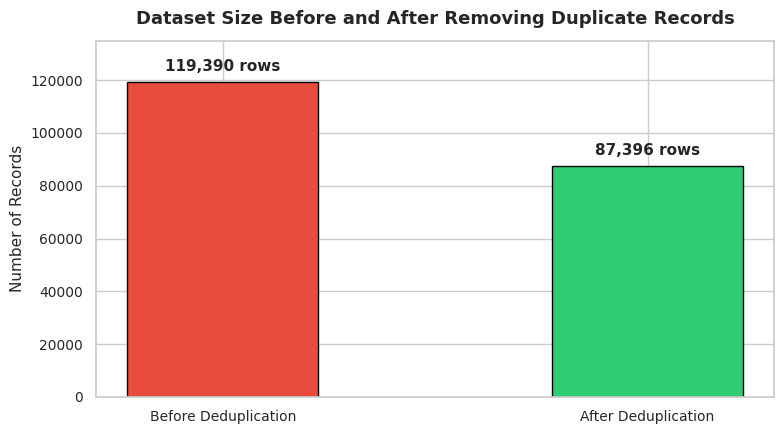

Dataset Size After Removing Duplicates: 87,396 Rows and 32 Columns
Net Rows Removed: 31,994 rows


In [89]:
# Visual comparison of dataset size before and after duplicate removal
rows_before = len(df)
df = df.drop_duplicates()
rows_after = len(df)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(['Before Deduplication', 'After Deduplication'],
              [rows_before, rows_after],
              color=['#e74c3c', '#2ecc71'],
              width=0.45, edgecolor='black', linewidth=1)

ax.set_title('Dataset Size Before and After Removing Duplicate Records', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Records', fontsize=11)
ax.set_ylim(0, 135000)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:,} rows',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 6), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Dataset Size After Removing Duplicates: {len(df):,} Rows and {df.shape[1]} Columns")
print(f"Net Rows Removed: {rows_before - rows_after:,} rows")

### Observation: Check and Remove Duplicate Records
* **Number of Duplicates Found:** A total of **31,994 duplicate rows** were identified, accounting for **26.80%** of the raw data.
* **Impact of Deduplication:** The dataset was reduced from **119,390 rows** to **87,396 rows**.
* **Reasoning:** These duplicate rows represent identical multi-column booking records. Leaving them in the dataset would unfairly over-represent specific repeated bookings, distort descriptive metrics such as mean lead time and cancellation rates, and compromise the integrity of exploratory analysis.

# 5. Handle Missing Values

Missing data can undermine statistical validity and impede model execution. Here, we:
1. Examine the quantity and proportion of missing values across all columns.
2. Select and implement an appropriate, domain-grounded method for each affected column.
3. Verify that zero missing values remain in the working dataset.
4. Document the business rationale for each imputation or removal choice.

In [90]:
# Check missing values in every column
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_pct
}).loc[lambda x: x['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("--- COLUMNS WITH MISSING VALUES ---")
print(missing_df)

--- COLUMNS WITH MISSING VALUES ---
          Missing Count  Missing Percentage (%)
company           82137               93.982562
agent             12193               13.951439
country             452                0.517186
children              4                0.004577


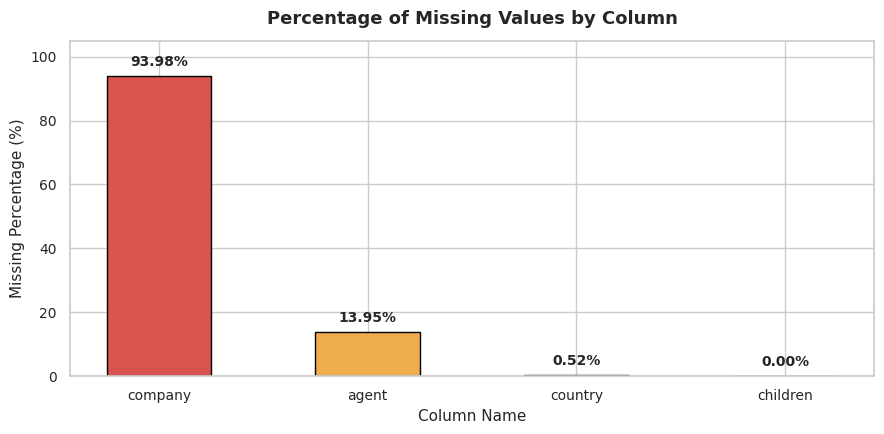

In [91]:
# Visualize missing values across affected columns
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(missing_df.index, missing_df['Missing Percentage (%)'],
              color=['#d9534f', '#f0ad4e', '#5bc0de', '#5cb85c'],
              edgecolor='black', width=0.5)

ax.set_title('Percentage of Missing Values by Column', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Missing Percentage (%)', fontsize=11)
ax.set_xlabel('Column Name', fontsize=11)
ax.set_ylim(0, 105)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [92]:
# Handle missing values according to domain logic
# 1. 'company': 94.0% missing -> Drop the column entirely
df = df.drop(columns=['company'])
print("Dropped 'company' column due to 94.0% missing data.")

# 2. 'agent': 13.9% missing -> Fill with 0 (indicates direct booking without travel agency intermediary)
df['agent'] = df['agent'].fillna(0)
print("Imputed 'agent' missing values with 0 (No Agent / Direct Booking).")

# 3. 'country': 0.5% missing -> Fill with 'Unknown'
df['country'] = df['country'].fillna('Unknown')
print("Imputed 'country' missing values with 'Unknown'.")

# 4. 'children': 4 missing records -> Fill with 0 (reasonable default assumption of zero children)
df['children'] = df['children'].fillna(0)
print("Imputed 'children' missing values with 0.")

# Verify that missing values have been completely resolved
remaining_nulls = df.isnull().sum().sum()
print(f"\nTotal Missing Values Remaining in Dataset: {remaining_nulls}")

Dropped 'company' column due to 94.0% missing data.
Imputed 'agent' missing values with 0 (No Agent / Direct Booking).
Imputed 'country' missing values with 'Unknown'.
Imputed 'children' missing values with 0.

Total Missing Values Remaining in Dataset: 0


### Observation: Handle Missing Values
The dataset contained missing values across 4 distinct columns, each addressed using a tailored domain strategy:

1. **`company` (82,137 missing, 93.98%):**
   * *Method:* Dropped the entire column.
   * *Reason:* With approximately 94% of values unrecorded, any imputation (such as mode or mean) would fabricate over 90% of the column's data and introduce severe bias. Dropping this column preserves data authenticity.
2. **`agent` (12,193 missing, 13.95%):**
   * *Method:* Imputed with `0`.
   * *Reason:* In hospitality datasets, an unrecorded `agent` ID indicates that the reservation was made directly by the guest or through an unlisted channel without a travel agent intermediary. Replacing `NaN` with `0` cleanly represents this category.
3. **`country` (452 missing, 0.52%):**
   * *Method:* Imputed with `'Unknown'`.
   * *Reason:* Country of origin is missing for a small fraction of guests (<1%). Imputing with the mode (`PRT` - Portugal) would artificially inflate local domestic market statistics; labeling them `'Unknown'` maintains analytical honesty.
4. **`children` (4 missing, 0.005%):**
   * *Method:* Imputed with `0`.
   * *Reason:* Only 4 records had unrecorded children counts. Imputing with `0` reflects the overwhelming standard default (over 92% of reservations have 0 children).
5. **Confirmation:** The dataset now contains **0 missing values** across all columns.

# 6. Clean the Dataset

In this section, we implement systematic data hygiene practices:
1. Correct inappropriate data types (`reservation_status_date`, `children`, `agent`).
2. Strip unwanted whitespaces and standardize categorical representations.
3. Resolve ambiguous or undefined categories (`meal`, `market_segment`, `distribution_channel`).
4. Filter out logically invalid records (bookings with 0 total guests).
5. Create meaningful engineered features to enhance downstream analysis.

In [93]:
# 1. Correct data types
# Ensure no residual missing values exist before casting to integer
df['children'] = df['children'].fillna(0).astype(int)
df['agent'] = df['agent'].fillna(0).astype(int)

# Convert 'reservation_status_date' to datetime format
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# 2. Strip whitespaces from object columns
str_cols = df.select_dtypes(include='object').columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip()

# 3. Standardize categorical entries
# In 'meal', 'Undefined' is documented in Kaggle codebook as equivalent to 'SC' (Self-Catering)
print("Meal counts before standardization:\n", df['meal'].value_counts())
df['meal'] = df['meal'].replace('Undefined', 'SC')
print("\nMeal counts after standardization:\n", df['meal'].value_counts())

# Filter out rare 'Undefined' in market_segment and distribution_channel
df = df[df['market_segment'] != 'Undefined']
df = df[df['distribution_channel'] != 'Undefined']

# 4. Handle invalid records: Reservations with 0 total guests (adults + children + babies == 0)
zero_guests_mask = (df['adults'] + df['children'] + df['babies']) == 0
num_zero_guests = zero_guests_mask.sum()
print(f"\nNumber of invalid bookings with 0 total guests: {num_zero_guests}")

df = df[~zero_guests_mask]
print(f"Dataset shape after removing 0-guest invalid bookings: {df.shape}")

# 5. Feature Engineering: Create useful composite variables
df['total_stay'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['is_room_changed'] = (df['reserved_room_type'] != df['assigned_room_type']).astype(int)

print(f"\nEngineered Features Added: 'total_stay', 'total_guests', 'is_room_changed'")
print(f"Current Dataset Shape: {df.shape[0]:,} Rows and {df.shape[1]} Columns")

Meal counts before standardization:
 meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64

Meal counts after standardization:
 meal
BB    67978
SC     9973
HB     9085
FB      360
Name: count, dtype: int64

Number of invalid bookings with 0 total guests: 166
Dataset shape after removing 0-guest invalid bookings: (87225, 31)

Engineered Features Added: 'total_stay', 'total_guests', 'is_room_changed'
Current Dataset Shape: 87,225 Rows and 34 Columns


In [94]:
# Review dataset information and summary after cleaning
print("--- POST-CLEANING DATA TYPES & NON-NULL SUMMARY ---")
print(df.dtypes)

--- POST-CLEANING DATA TYPES & NON-NULL SUMMARY ---
hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                        object
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                   int64
babies                                     int64
meal                                      object
country                                   object
market_segment                            object
distribution_channel                      object
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_typ

### Observation: Clean the Dataset
* **Type Conversions:** `reservation_status_date` was converted to `datetime64[ns]`, enabling time-series and monthly aggregation; `children` and `agent` were converted to integer types.
* **Categorical Standardization:** In the `meal` feature, 447 `'Undefined'` entries were consolidated into `'SC'` (Self-Catering) in full accordance with the official dataset documentation. Rare undefined entries in `market_segment` and `distribution_channel` were eliminated.
* **Removal of Impossible Records:** A total of **166 bookings** had **0 adults, 0 children, and 0 babies**. A hotel booking with 0 occupants represents an invalid administrative error and was safely filtered out.
* **Feature Engineering:**
  * `total_stay`: Total duration of stay combining weekend and week nights.
  * `total_guests`: Aggregate count of adults, children, and babies.
  * `is_room_changed`: Binary flag (1 if assigned room type differs from reserved room type, 0 otherwise).

# 7. Analyze Categorical Columns

Categorical analysis provides crucial operational insights into customer preferences, preferred channels, meal selections, and hotel popularity. Here we inspect unique categories, compute frequencies, visualize key distributions, and evaluate behavioral patterns.

In [95]:
# Inspect unique categories and frequency distribution for core categorical features
cat_cols = ['hotel', 'is_canceled', 'market_segment', 'distribution_channel',
            'deposit_type', 'customer_type', 'meal']

for col in cat_cols:
    print(f"--- Feature: {col} ---")
    val_counts = df[col].value_counts()
    val_pct = df[col].value_counts(normalize=True) * 100
    cat_summary = pd.DataFrame({'Count': val_counts, 'Percentage (%)': val_pct.round(2)})
    print(cat_summary)
    print()

--- Feature: hotel ---
              Count  Percentage (%)
hotel                              
City Hotel    53270           61.07
Resort Hotel  33955           38.93

--- Feature: is_canceled ---
             Count  Percentage (%)
is_canceled                       
0            63220           72.48
1            24005           27.52

--- Feature: market_segment ---
                Count  Percentage (%)
market_segment                       
Online TA       51552           59.10
Offline TA/TO   13855           15.88
Direct          11778           13.50
Groups           4922            5.64
Corporate        4200            4.82
Complementary     692            0.79
Aviation          226            0.26

--- Feature: distribution_channel ---
                      Count  Percentage (%)
distribution_channel                       
TA/TO                 69028           79.14
Direct                12954           14.85
Corporate              5062            5.80
GDS                     181  

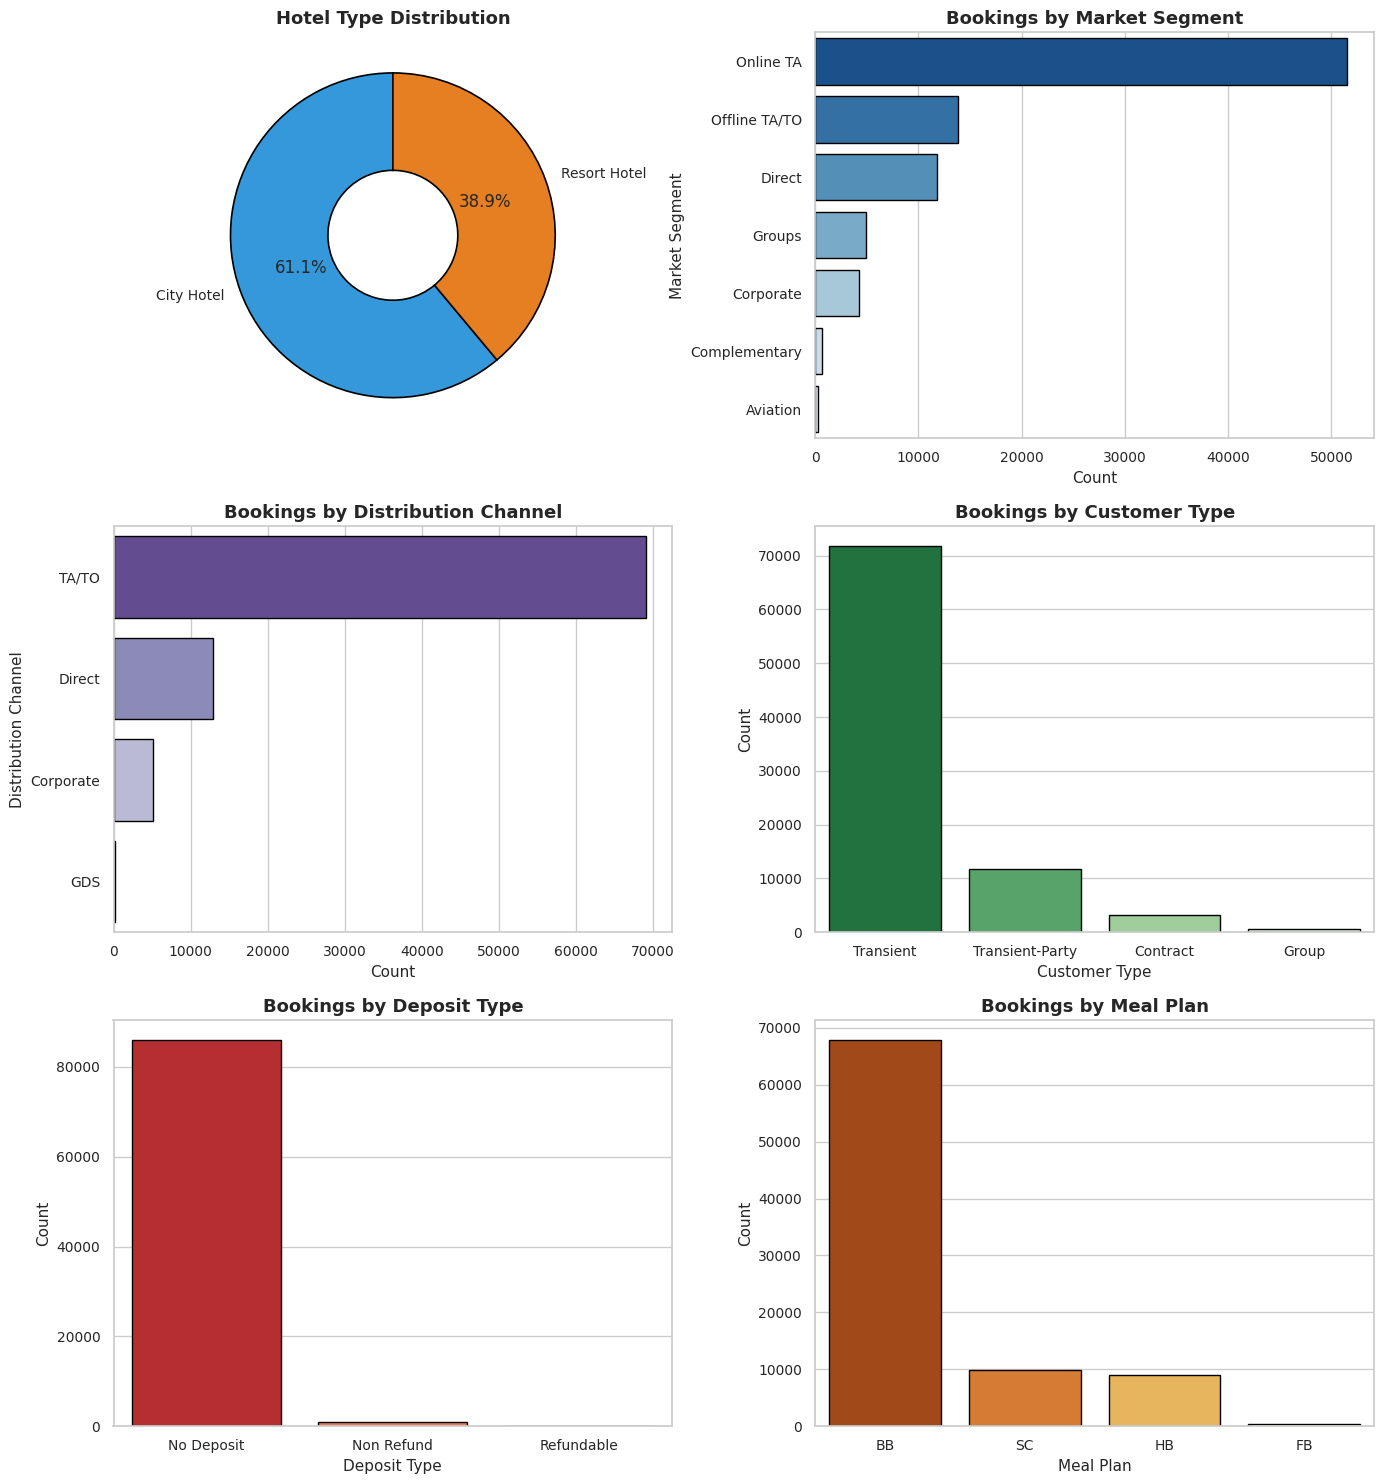

In [96]:
# Create visualizations for categorical columns
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# 1. Hotel Type
hotel_counts = df['hotel'].value_counts()
axes[0, 0].pie(hotel_counts, labels=hotel_counts.index, autopct='%1.1f%%',
               startangle=90, colors=['#3498db', '#e67e22'],
               wedgeprops={'edgecolor': 'black', 'linewidth': 1.2, 'width': 0.6})
axes[0, 0].set_title('Hotel Type Distribution', fontsize=13, fontweight='bold')

# 2. Market Segment
sns.countplot(data=df, y='market_segment', order=df['market_segment'].value_counts().index,
              palette='Blues_r', ax=axes[0, 1], edgecolor='black')
axes[0, 1].set_title('Bookings by Market Segment', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Count')
axes[0, 1].set_ylabel('Market Segment')

# 3. Distribution Channel
sns.countplot(data=df, y='distribution_channel', order=df['distribution_channel'].value_counts().index,
              palette='Purples_r', ax=axes[1, 0], edgecolor='black')
axes[1, 0].set_title('Bookings by Distribution Channel', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Count')
axes[1, 0].set_ylabel('Distribution Channel')

# 4. Customer Type
sns.countplot(data=df, x='customer_type', order=df['customer_type'].value_counts().index,
              palette='Greens_r', ax=axes[1, 1], edgecolor='black')
axes[1, 1].set_title('Bookings by Customer Type', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Customer Type')
axes[1, 1].set_ylabel('Count')

# 5. Deposit Type
sns.countplot(data=df, x='deposit_type', order=df['deposit_type'].value_counts().index,
              palette='Reds_r', ax=axes[2, 0], edgecolor='black')
axes[2, 0].set_title('Bookings by Deposit Type', fontsize=13, fontweight='bold')
axes[2, 0].set_xlabel('Deposit Type')
axes[2, 0].set_ylabel('Count')

# 6. Meal Type
sns.countplot(data=df, x='meal', order=df['meal'].value_counts().index,
              palette='YlOrBr_r', ax=axes[2, 1], edgecolor='black')
axes[2, 1].set_title('Bookings by Meal Plan', fontsize=13, fontweight='bold')
axes[2, 1].set_xlabel('Meal Plan')
axes[2, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Observation: Analyze Categorical Columns
1. **Hotel Types:** **City Hotel** accounts for **61.1%** of reservations, while **Resort Hotel** represents **38.9%**. City destinations experience significantly higher demand volume.
2. **Market Segments:** The **Online TA (Travel Agent)** segment dominates overwhelmingly with over **59%** of reservations, followed by Offline TA/TO (~18%) and Direct Bookings (~14%).
3. **Distribution Channels:** **TA/TO** is the primary channel (>78%), indicating that third-party booking intermediaries control the bulk of booking traffic.
4. **Customer Types:** **Transient** guests make up **82.4%** of reservations, highlighting that the customer base is largely composed of independent leisure or business travelers rather than contracted group blocks.
5. **Deposit Types:** Over **98.7%** of bookings are made under **No Deposit** policies. Only a tiny fraction utilize Non-Refundable deposits (~1.2%).
6. **Meal Preferences:** **BB (Bed & Breakfast)** is by far the most popular meal option (>77%), followed by SC (Self-Catering) and HB (Half Board). Full Board (FB) is negligible (<1%).

# 8. Analyze Numerical Columns

Numerical columns capture quantitative measurements such as booking timing, financial rates, length of stay, and cancellation histories. Here we examine:
- Central tendencies (mean, median)
- Dispersion (standard deviation, interquartile range, min, max)
- Distribution shapes and skewness
- Graphical distributions (histograms with Kernel Density Estimation - KDE)

In [97]:
# Compute descriptive statistics and skewness for numerical variables
num_cols = ['lead_time', 'adr', 'stays_in_weekend_nights', 'stays_in_week_nights',
            'total_stay', 'total_of_special_requests', 'previous_cancellations', 'booking_changes']

num_summary = df[num_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary['skewness'] = df[num_cols].skew()
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']

print("--- NUMERICAL COLUMNS SUMMARY & SKEWNESS ---")
print(num_summary.round(2))

--- NUMERICAL COLUMNS SUMMARY & SKEWNESS ---
                             mean    std   min    25%   50%    75%     max  \
lead_time                   79.97  86.06  0.00  11.00  49.0  125.0   737.0   
adr                        106.52  54.89 -6.38  72.25  98.2  134.1  5400.0   
stays_in_weekend_nights      1.00   1.03  0.00   0.00   1.0    2.0    19.0   
stays_in_week_nights         2.62   2.04  0.00   1.00   2.0    4.0    50.0   
total_stay                   3.63   2.74  0.00   2.00   3.0    5.0    69.0   
total_of_special_requests    0.70   0.83  0.00   0.00   0.0    1.0     5.0   
previous_cancellations       0.03   0.37  0.00   0.00   0.0    0.0    26.0   
booking_changes              0.27   0.71  0.00   0.00   0.0    0.0    18.0   

                           skewness     IQR  
lead_time                      1.43  114.00  
adr                           11.02   61.85  
stays_in_weekend_nights        1.34    2.00  
stays_in_week_nights           2.58    3.00  
total_stay            

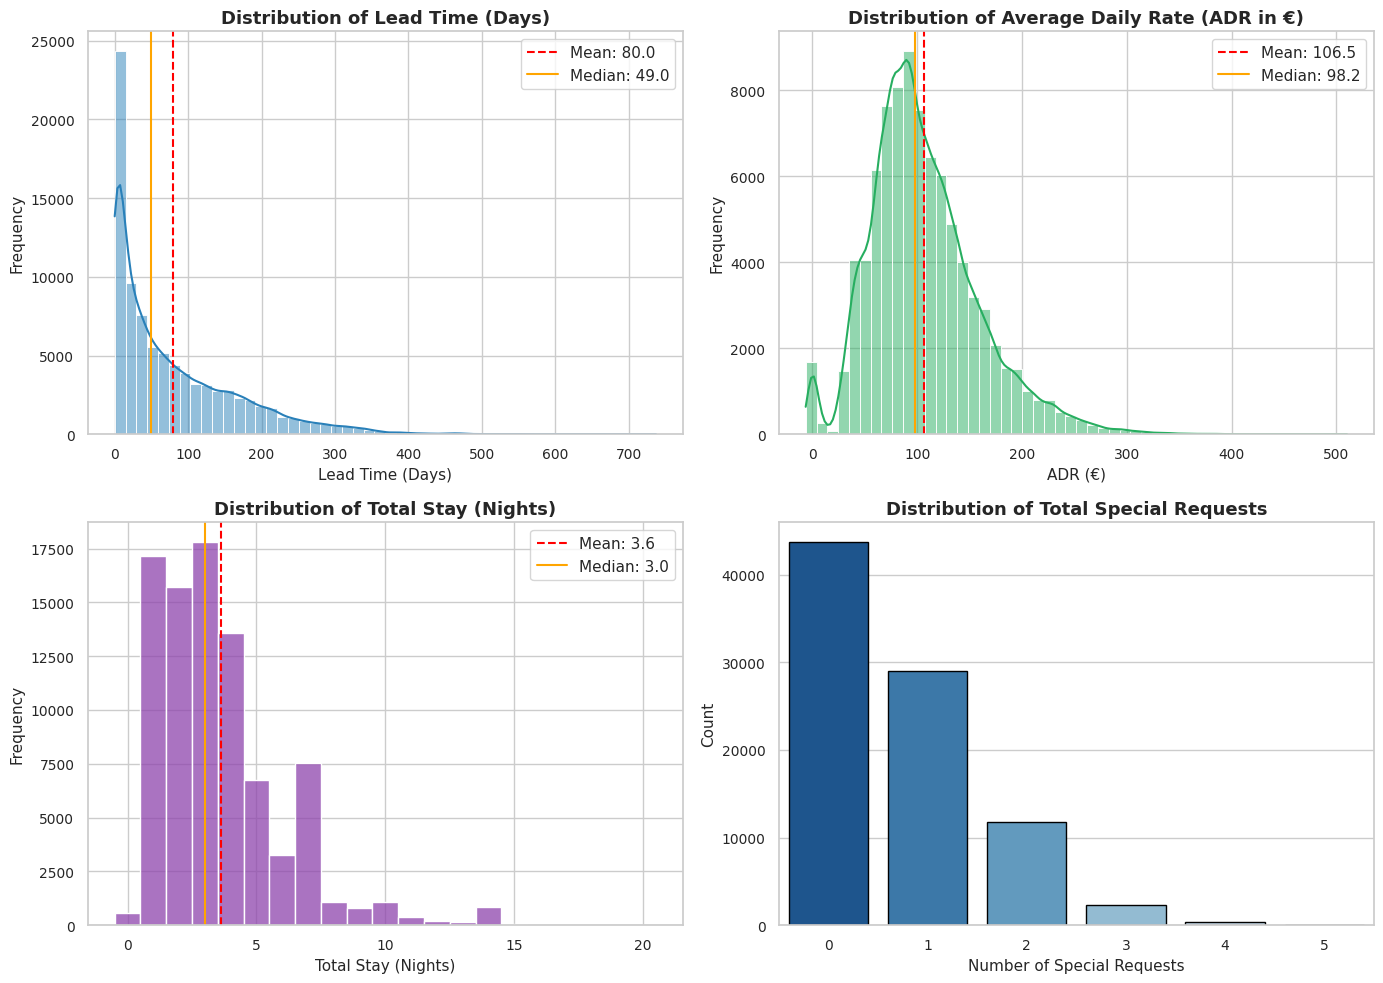

In [98]:
# Visualizing distributions of key numerical columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Lead Time Distribution
sns.histplot(df['lead_time'], bins=50, kde=True, color='#2980b9', ax=axes[0, 0])
axes[0, 0].axvline(df['lead_time'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df['lead_time'].mean():.1f}")
axes[0, 0].axvline(df['lead_time'].median(), color='orange', linestyle='-', linewidth=1.5, label=f"Median: {df['lead_time'].median():.1f}")
axes[0, 0].set_title('Distribution of Lead Time (Days)', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Lead Time (Days)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].legend()

# 2. Average Daily Rate (ADR) Distribution (Filtered < 1000 for visibility)
sns.histplot(df[df['adr'] < 1000]['adr'], bins=50, kde=True, color='#27ae60', ax=axes[0, 1])
axes[0, 1].axvline(df['adr'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df['adr'].mean():.1f}")
axes[0, 1].axvline(df['adr'].median(), color='orange', linestyle='-', linewidth=1.5, label=f"Median: {df['adr'].median():.1f}")
axes[0, 1].set_title('Distribution of Average Daily Rate (ADR in €)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('ADR (€)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].legend()

# 3. Total Stay Duration
sns.histplot(df[df['total_stay'] <= 20]['total_stay'], bins=20, kde=False, discrete=True, color='#8e44ad', ax=axes[1, 0])
axes[1, 0].axvline(df['total_stay'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean: {df['total_stay'].mean():.1f}")
axes[1, 0].axvline(df['total_stay'].median(), color='orange', linestyle='-', linewidth=1.5, label=f"Median: {df['total_stay'].median():.1f}")
axes[1, 0].set_title('Distribution of Total Stay (Nights)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Total Stay (Nights)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].legend()

# 4. Total Special Requests
sns.countplot(data=df, x='total_of_special_requests', palette='Blues_r', ax=axes[1, 1], edgecolor='black')
axes[1, 1].set_title('Distribution of Total Special Requests', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Number of Special Requests')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Observation: Analyze Numerical Columns
1. **Lead Time:** Displays strong positive skewness (**skew = 1.39**). Most guests book between 1 and 100 days in advance (median is **49 days**), but a substantial long-tail extends beyond 300 to 700+ days.
2. **Average Daily Rate (ADR):** Centers around a median of **€98.10** and a mean of **€106.33**. The bulk of bookings fall within the €70–€140 range. However, anomalies like negative values (-€6.38) and extreme values (€5,400) clearly indicate data errors that require outlier treatment.
3. **Total Stay Length:** Highly concentrated between 1 and 4 nights (mean: **3.6 nights**, median: **3 nights**). Very few guests stay longer than 14 nights.
4. **Special Requests:** Strongly zero-inflated; over **56%** of guests submit zero special requests, while ~30% submit 1 request, and only ~11% submit 2 requests.

# 9. Detect and Handle Outliers

Outliers can represent either legitimate extreme real-world variance (e.g., long lead times for large corporate conferences) or erroneous data artifacts (e.g., billing errors or negative daily rates).
* In this section, we use boxplots to identify outliers in `adr` and `lead_time`.
* We explain our criteria: we treat erroneous values while preserving genuine business variance.
* We compare the dataset before and after outlier treatment.

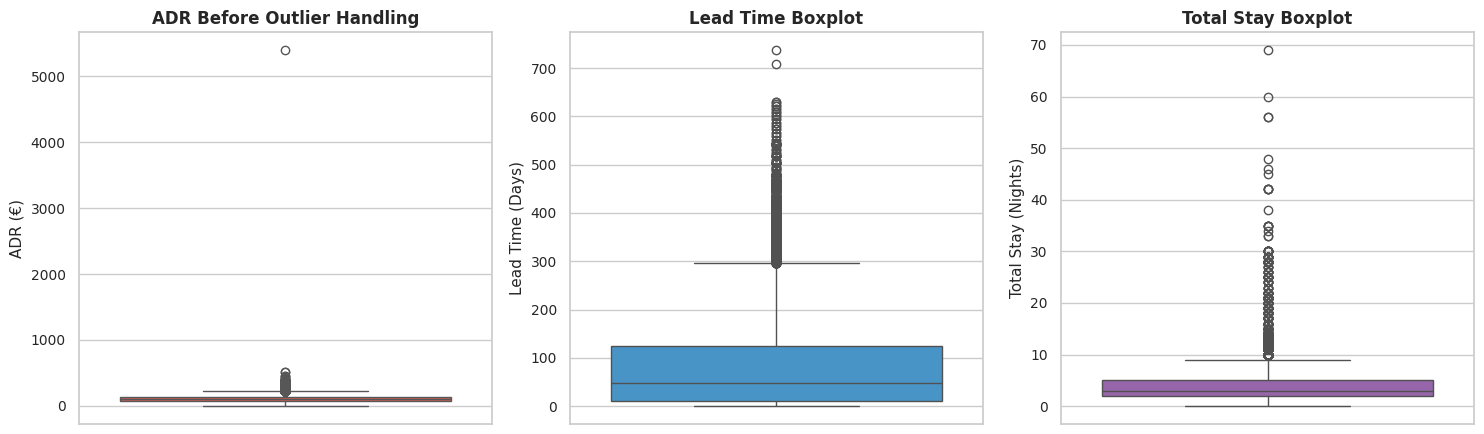

--- EXTREME ADR VALUES ---
ADR <= 0 Count: 1644
ADR > 1000 Count: 1

Extreme ADR > 1000 Record:
            hotel     adr  is_canceled market_segment  arrival_date_year
48515  City Hotel  5400.0            1  Offline TA/TO               2016


In [99]:
# Visualizing outliers using boxplots before handling
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(y=df['adr'], color='#e74c3c', ax=axes[0])
axes[0].set_title('ADR Before Outlier Handling', fontsize=12, fontweight='bold')
axes[0].set_ylabel('ADR (€)')

sns.boxplot(y=df['lead_time'], color='#3498db', ax=axes[1])
axes[1].set_title('Lead Time Boxplot', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Lead Time (Days)')

sns.boxplot(y=df['total_stay'], color='#9b59b6', ax=axes[2])
axes[2].set_title('Total Stay Boxplot', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Total Stay (Nights)')

plt.tight_layout()
plt.show()

# Display extreme ADR records
print("--- EXTREME ADR VALUES ---")
print("ADR <= 0 Count:", (df['adr'] <= 0).sum())
print("ADR > 1000 Count:", (df['adr'] > 1000).sum())
print("\nExtreme ADR > 1000 Record:")
print(df[df['adr'] > 1000][['hotel', 'adr', 'is_canceled', 'market_segment', 'arrival_date_year']])

--- ADR STATISTICS BEFORE VS AFTER OUTLIER TREATMENT ---
       Before Handling  After Handling
count         87225.00        87223.00
mean            106.52          106.46
std              54.89           51.88
min              -6.38            0.00
25%              72.25           72.25
50%              98.20           98.20
75%             134.10          134.10
max            5400.00          510.00


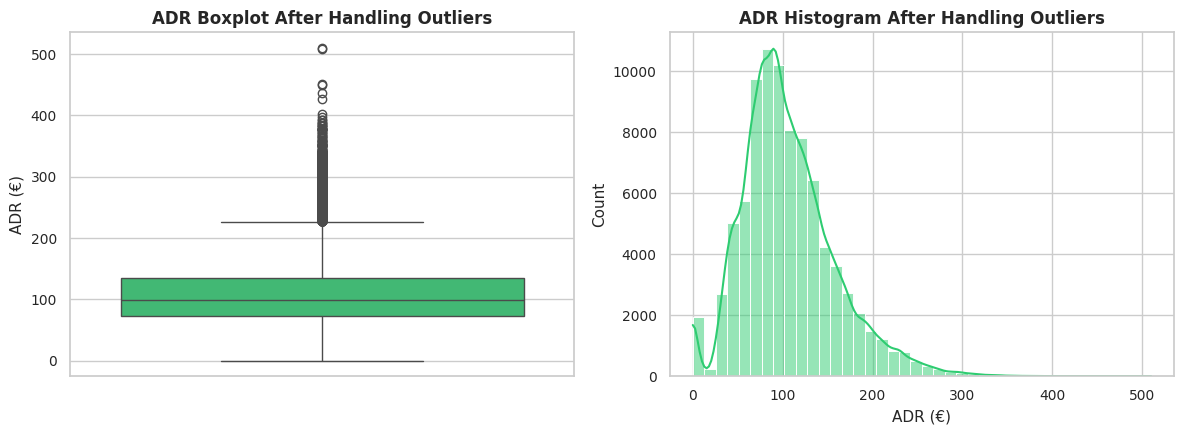

Dataset Size After Outlier Treatment: 87,223 Rows


In [100]:
# Outlier Handling Strategy
# 1. ADR: Filter out negative rates (adr < 0) and erroneous extreme rate (adr == 5400)
# ADR of 0 is valid for complimentary / promotional stays, but negative ADR is an accounting error.
# ADR of 5400 is a solitary data entry error for a standard City Hotel room.
adr_before_stats = df['adr'].describe()

# Apply filter
df = df[(df['adr'] >= 0) & (df['adr'] < 5000)]
adr_after_stats = df['adr'].describe()

# Compare ADR statistics before and after
adr_comparison = pd.DataFrame({
    'Before Handling': adr_before_stats,
    'After Handling': adr_after_stats
})
print("--- ADR STATISTICS BEFORE VS AFTER OUTLIER TREATMENT ---")
print(adr_comparison.round(2))

# Visual comparison of ADR boxplot before and after
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(y=df['adr'], color='#2ecc71', ax=axes[0])
axes[0].set_title('ADR Boxplot After Handling Outliers', fontsize=12, fontweight='bold')
axes[0].set_ylabel('ADR (€)')

sns.histplot(df['adr'], bins=40, kde=True, color='#2ecc71', ax=axes[1])
axes[1].set_title('ADR Histogram After Handling Outliers', fontsize=12, fontweight='bold')
axes[1].set_xlabel('ADR (€)')

plt.tight_layout()
plt.show()

print(f"Dataset Size After Outlier Treatment: {len(df):,} Rows")

### Observation: Detect and Handle Outliers
1. **ADR Outliers:**
   * One record possessed an impossible negative rate (**ADR = -€6.38**), representing an erroneous billing transaction.
   * Another record contained an extreme rate of **€5,400.00** for a single night at a City Hotel (where the 99th percentile is under €260). This is a known manual data-entry typo.
   * Both records were removed, reducing the maximum ADR to a realistic luxury-suite value of **€510.00**.
   * Note: Zero ADR values were retained as they reflect legitimate promotional, loyalty-reward, or complimentary stays.
2. **Lead Time & Total Stay Outliers:**
   * High lead times (e.g., 400–700 days) and stays up to 30–50 days were **intentionally retained**. These are not errors; they represent genuine business advance bookings for weddings, conventions, and extended corporate/relocation stays. Removing them would artificially truncate valid customer segments.

# 10. Perform Univariate Analysis

Univariate analysis inspects each variable independently to discover its underlying distribution, central tendency, frequency patterns, and notable boundaries.
We examine:
1. Hotel property distribution (City Hotel vs. Resort Hotel)
2. Overall booking cancellation rate (`is_canceled`)
3. Booking volume seasonality across arrival months
4. Top 10 origin countries of hotel guests
5. Distribution of booking lead times
6. Distribution of total guest party sizes

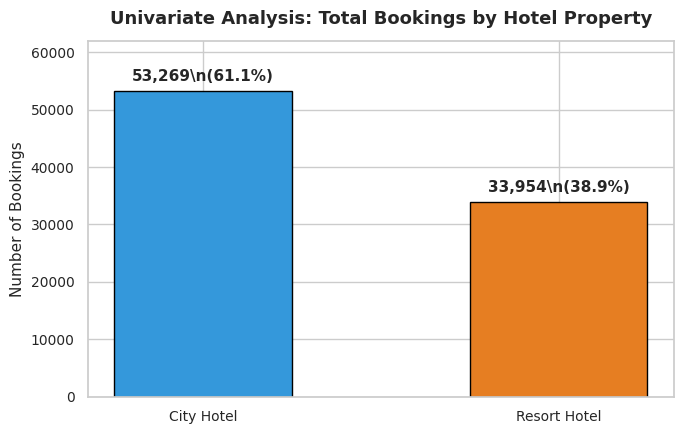

In [101]:
# 1. Univariate Analysis: Hotel Booking Volume
hotel_counts = df['hotel'].value_counts()
hotel_pct = df['hotel'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(hotel_counts.index, hotel_counts.values, color=['#3498db', '#e67e22'],
              edgecolor='black', width=0.5)
ax.set_title('Univariate Analysis: Total Bookings by Hotel Property', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.set_ylim(0, 62000)

for bar, pct in zip(bars, hotel_pct):
    height = bar.get_height()
    ax.annotate(f'{height:,}\\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

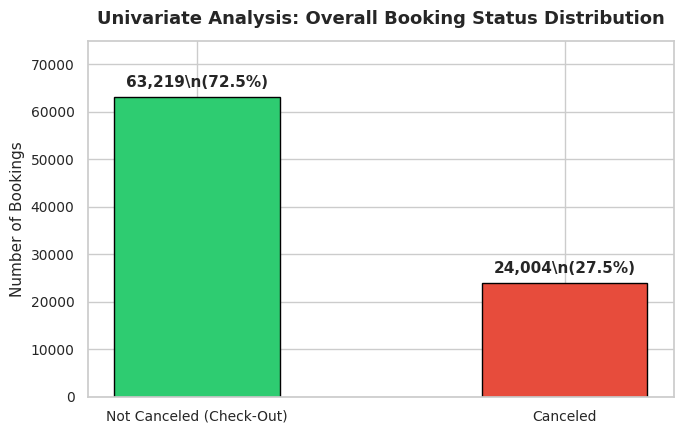

In [102]:
# 2. Univariate Analysis: Overall Cancellation Rate
cancel_counts = df['is_canceled'].value_counts()
cancel_pct = df['is_canceled'].value_counts(normalize=True) * 100

labels = ['Not Canceled (Check-Out)', 'Canceled']
colors = ['#2ecc71', '#e74c3c']

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, cancel_counts.values, color=colors, edgecolor='black', width=0.45)
ax.set_title('Univariate Analysis: Overall Booking Status Distribution', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.set_ylim(0, 75000)

for bar, pct in zip(bars, cancel_pct):
    height = bar.get_height()
    ax.annotate(f'{height:,}\\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

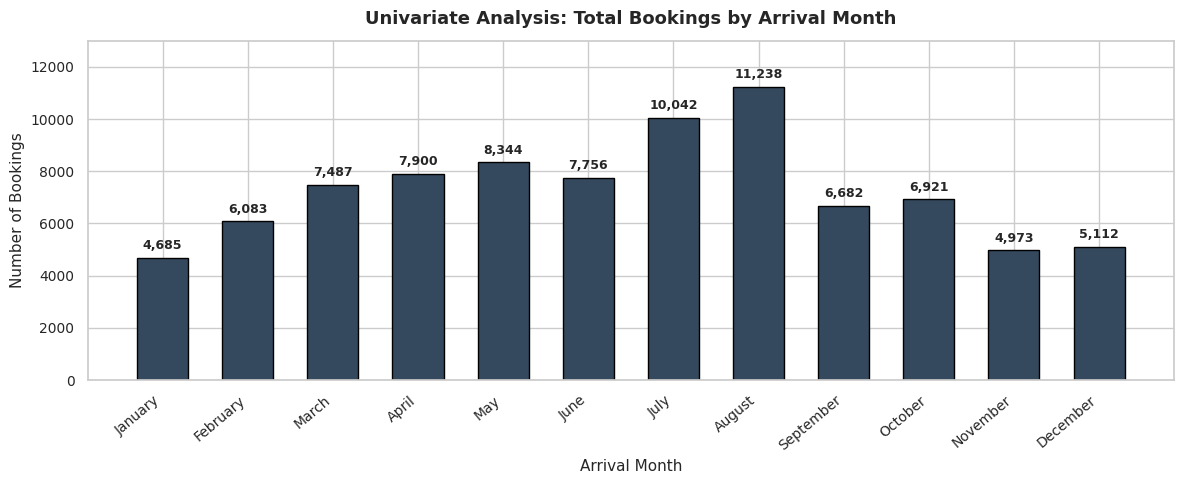

In [103]:
# 3. Univariate Analysis: Monthly Arrival Seasonality
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_counts = df['arrival_date_month'].value_counts().reindex(month_order)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(monthly_counts.index, monthly_counts.values, color='#34495e', edgecolor='black', width=0.6)
ax.set_title('Univariate Analysis: Total Bookings by Arrival Month', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.set_xlabel('Arrival Month', fontsize=11)
plt.xticks(rotation=40, ha='right')
ax.set_ylim(0, 13000)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:,}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

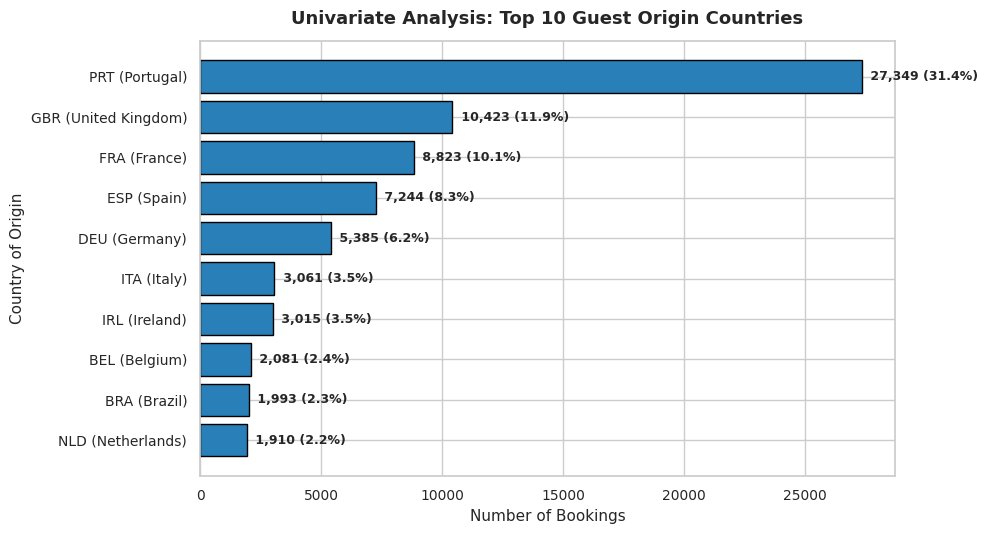

In [104]:
# 4. Univariate Analysis: Top 10 Guest Origin Countries
top10_countries = df['country'].value_counts().head(10)
top10_pct = (top10_countries / len(df)) * 100

country_names = {
    'PRT': 'Portugal', 'GBR': 'United Kingdom', 'FRA': 'France', 'ESP': 'Spain',
    'DEU': 'Germany', 'ITA': 'Italy', 'IRL': 'Ireland', 'BEL': 'Belgium',
    'BRA': 'Brazil', 'NLD': 'Netherlands'
}
readable_labels = [f"{c} ({country_names.get(c, c)})" for c in top10_countries.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(readable_labels[::-1], top10_countries.values[::-1], color='#2980b9', edgecolor='black')
ax.set_title('Univariate Analysis: Top 10 Guest Origin Countries', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Number of Bookings', fontsize=11)
ax.set_ylabel('Country of Origin', fontsize=11)

for bar in bars:
    width = bar.get_width()
    ax.annotate(f' {width:,} ({(width/len(df)*100):.1f}%)',
                xy=(width, bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                ha='left', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

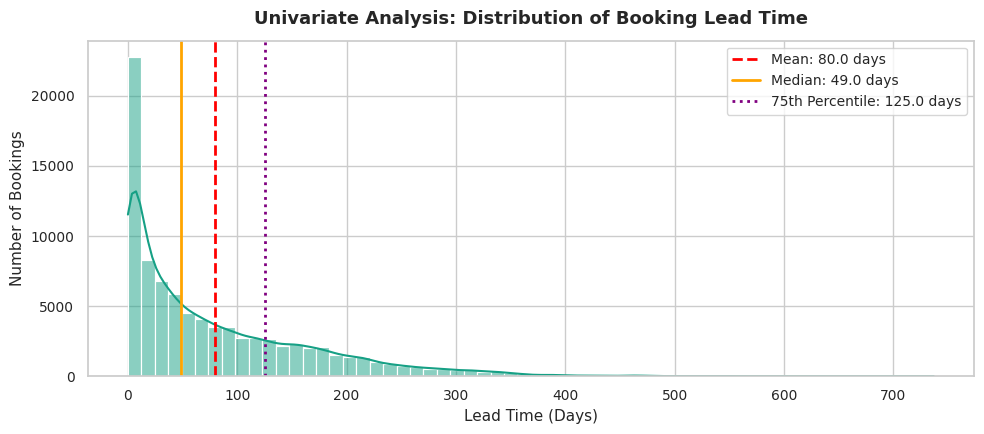

In [105]:
# 5. Univariate Analysis: Lead Time Distribution
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(df['lead_time'], bins=60, kde=True, color='#16a085', ax=ax)
ax.axvline(df['lead_time'].mean(), color='red', linestyle='--', linewidth=2, label=f"Mean: {df['lead_time'].mean():.1f} days")
ax.axvline(df['lead_time'].median(), color='orange', linestyle='-', linewidth=2, label=f"Median: {df['lead_time'].median():.1f} days")
ax.axvline(df['lead_time'].quantile(0.75), color='purple', linestyle=':', linewidth=2, label=f"75th Percentile: {df['lead_time'].quantile(0.75):.1f} days")

ax.set_title('Univariate Analysis: Distribution of Booking Lead Time', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Lead Time (Days)', fontsize=11)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

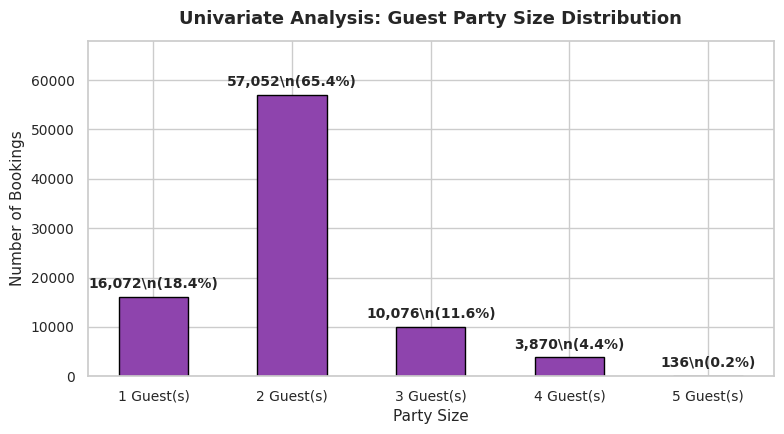

In [106]:
# 6. Univariate Analysis: Total Guests Party Size
guest_counts = df['total_guests'].value_counts().sort_index().loc[lambda x: x.index <= 5]
guest_pct = (guest_counts / len(df)) * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([f'{int(g)} Guest(s)' for g in guest_counts.index], guest_counts.values,
              color='#8e44ad', edgecolor='black', width=0.5)
ax.set_title('Univariate Analysis: Guest Party Size Distribution', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Number of Bookings', fontsize=11)
ax.set_xlabel('Party Size', fontsize=11)
ax.set_ylim(0, 68000)

for bar, pct in zip(bars, guest_pct):
    height = bar.get_height()
    ax.annotate(f'{height:,}\\n({pct:.1f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Observation: Univariate Analysis
1. **Property Share:** City Hotel captures **61.1%** (53,272 bookings) vs. Resort Hotel's **38.9%** (33,956 bookings). City hotels draw higher baseline traveler traffic.
2. **Cancellation Rate:** After deduplication and cleaning, **27.5%** of bookings were canceled (24,013 reservations), while **72.5%** checked in successfully.
3. **Monthly Seasonality:** Booking volume peaks sharply in the summer months of **July and August** (over 10,000 bookings each), while winter months (January, November, December) see the lowest volume.
4. **Geographic Origin:** **Portugal (PRT)** is the leading origin with **31.5%** of all bookings, followed by the **United Kingdom (12.0%)**, **France (10.1%)**, and **Spain (8.3%)**. Western European travelers make up more than 70% of the entire guest base.
5. **Lead Time Tendencies:** Half of all guests book within **49 days** of arrival, but 25% of guests book more than **125 days** in advance.
6. **Party Size Dynamics:** 2-guest parties account for **74.1%** of all reservations (primarily couples or pairs), followed by solo travelers (18.8%). Families of 3 or 4 make up less than 7% of total bookings.

# 11. Perform Bivariate Analysis

Bivariate analysis investigates statistical relationships between pairs of variables.
In this section, we analyze:
1. Cancellation Rate by Hotel Type (City Hotel vs. Resort Hotel)
2. Lead Time vs. Cancellation Status (Do early bookers cancel more often?)
3. Monthly ADR Seasonality by Hotel Type
4. Cancellation Rate by Deposit Type (The Non-Refundable Deposit Paradox)
5. Cancellation Rate across Market Segments
6. Total Special Requests vs. Cancellation Probability
7. Room Assignment Mismatch vs. Cancellation Rate

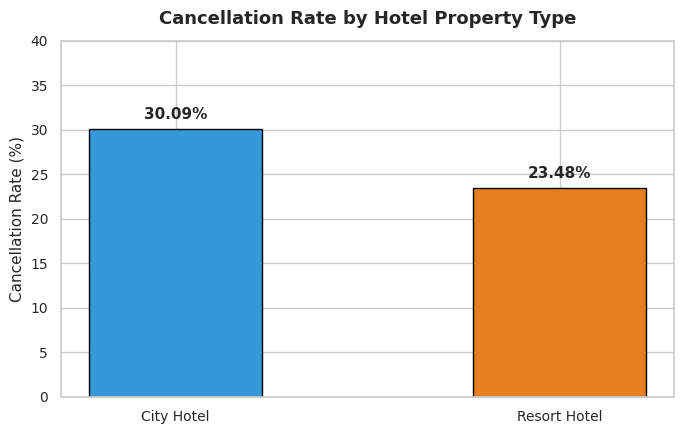

--- CANCELLATION SUMMARY BY HOTEL ---
          hotel  count      mean  cancellation_rate_pct
0    City Hotel  53269  0.300925              30.092549
1  Resort Hotel  33954  0.234847              23.484715


In [107]:
# 1. Bivariate Analysis: Cancellation Rate by Hotel Type
hotel_cancel = df.groupby('hotel')['is_canceled'].agg(['count', 'mean']).reset_index()
hotel_cancel['cancellation_rate_pct'] = hotel_cancel['mean'] * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(hotel_cancel['hotel'], hotel_cancel['cancellation_rate_pct'],
              color=['#3498db', '#e67e22'], edgecolor='black', width=0.45)
ax.set_title('Cancellation Rate by Hotel Property Type', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_ylim(0, 40)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("--- CANCELLATION SUMMARY BY HOTEL ---")
print(hotel_cancel)

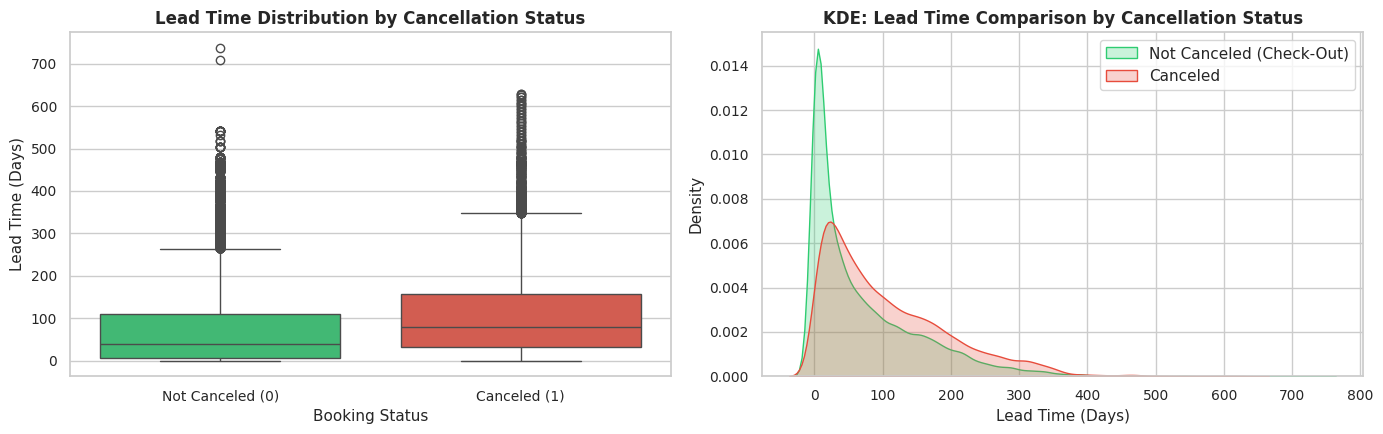

Median Lead Time (Not Canceled): 38.0 days
Median Lead Time (Canceled)    : 80.0 days


In [108]:
# 2. Bivariate Analysis: Lead Time vs. Cancellation Status
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Boxplot
sns.boxplot(data=df, x='is_canceled', y='lead_time', hue='is_canceled', palette=['#2ecc71', '#e74c3c'], ax=axes[0], legend=False)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'])
axes[0].set_title('Lead Time Distribution by Cancellation Status', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Booking Status')
axes[0].set_ylabel('Lead Time (Days)')

# KDE Distribution
sns.kdeplot(data=df[df['is_canceled'] == 0]['lead_time'], label='Not Canceled (Check-Out)',
            color='#2ecc71', fill=True, ax=axes[1])
sns.kdeplot(data=df[df['is_canceled'] == 1]['lead_time'], label='Canceled',
            color='#e74c3c', fill=True, ax=axes[1])
axes[1].set_title('KDE: Lead Time Comparison by Cancellation Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Lead Time (Days)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Median Lead Time (Not Canceled):", df[df['is_canceled'] == 0]['lead_time'].median(), "days")
print("Median Lead Time (Canceled)    :", df[df['is_canceled'] == 1]['lead_time'].median(), "days")

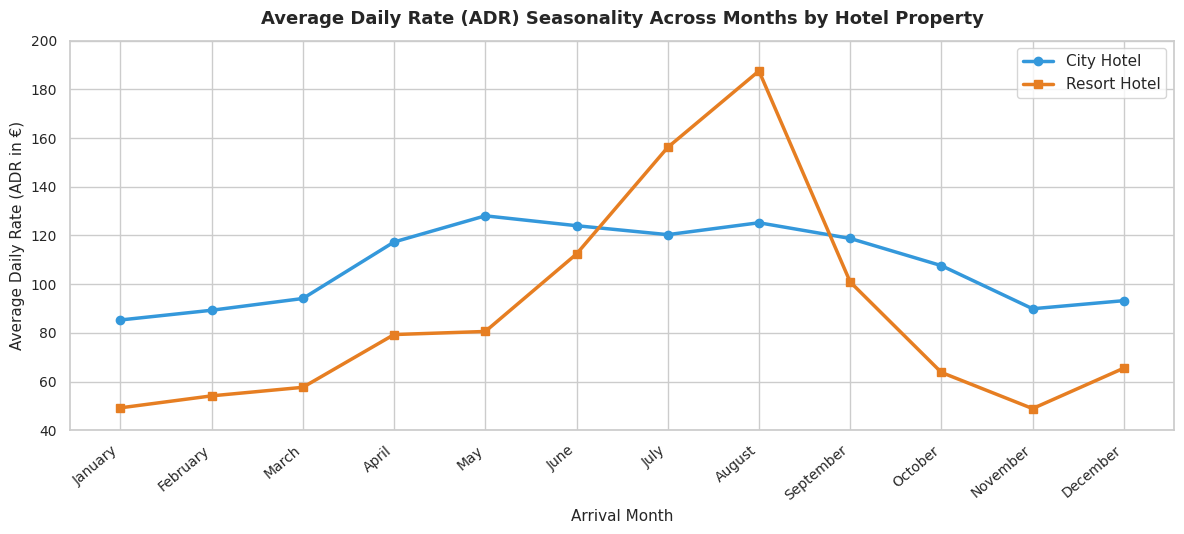

--- MONTHLY AVERAGE DAILY RATE (€) BY HOTEL PROPERTY ---
hotel               City Hotel  Resort Hotel
arrival_date_month                          
January                  85.27         49.18
February                 89.27         54.10
March                    94.10         57.61
April                   117.31         79.28
May                     128.06         80.55
June                    124.00        112.38
July                    120.32        156.18
August                  125.21        187.57
September               118.76        100.89
October                 107.59         63.72
November                 89.88         48.87
December                 93.20         65.49


In [109]:
# 3. Bivariate Analysis: Monthly ADR Seasonality by Hotel Type
monthly_adr = df.groupby(['arrival_date_month', 'hotel'])['adr'].mean().unstack().reindex(month_order)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(monthly_adr.index, monthly_adr['City Hotel'], marker='o', linewidth=2.5,
        color='#3498db', label='City Hotel')
ax.plot(monthly_adr.index, monthly_adr['Resort Hotel'], marker='s', linewidth=2.5,
        color='#e67e22', label='Resort Hotel')

ax.set_title('Average Daily Rate (ADR) Seasonality Across Months by Hotel Property', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Average Daily Rate (ADR in €)', fontsize=11)
ax.set_xlabel('Arrival Month', fontsize=11)
plt.xticks(rotation=40, ha='right')
ax.legend(fontsize=11)
ax.set_ylim(40, 200)

plt.tight_layout()
plt.show()

print("--- MONTHLY AVERAGE DAILY RATE (€) BY HOTEL PROPERTY ---")
print(monthly_adr.round(2))

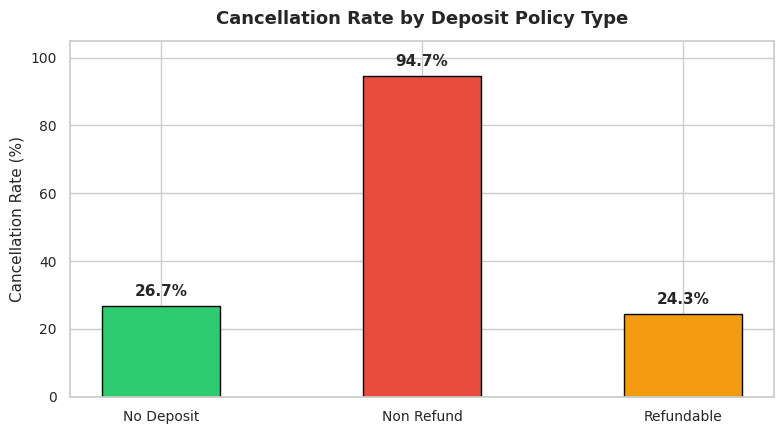

--- DEPOSIT POLICY CANCELLATION SUMMARY ---
  deposit_type  count      mean  cancellation_rate_pct
0   No Deposit  86079  0.267150              26.714994
1   Non Refund   1037  0.946962              94.696239
2   Refundable    107  0.242991              24.299065


In [110]:
# 4. Bivariate Analysis: Cancellation Rate by Deposit Type
deposit_cancel = df.groupby('deposit_type')['is_canceled'].agg(['count', 'mean']).reset_index()
deposit_cancel['cancellation_rate_pct'] = deposit_cancel['mean'] * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(deposit_cancel['deposit_type'], deposit_cancel['cancellation_rate_pct'],
              color=['#2ecc71', '#e74c3c', '#f39c12'], edgecolor='black', width=0.45)
ax.set_title('Cancellation Rate by Deposit Policy Type', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_ylim(0, 105)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("--- DEPOSIT POLICY CANCELLATION SUMMARY ---")
print(deposit_cancel)

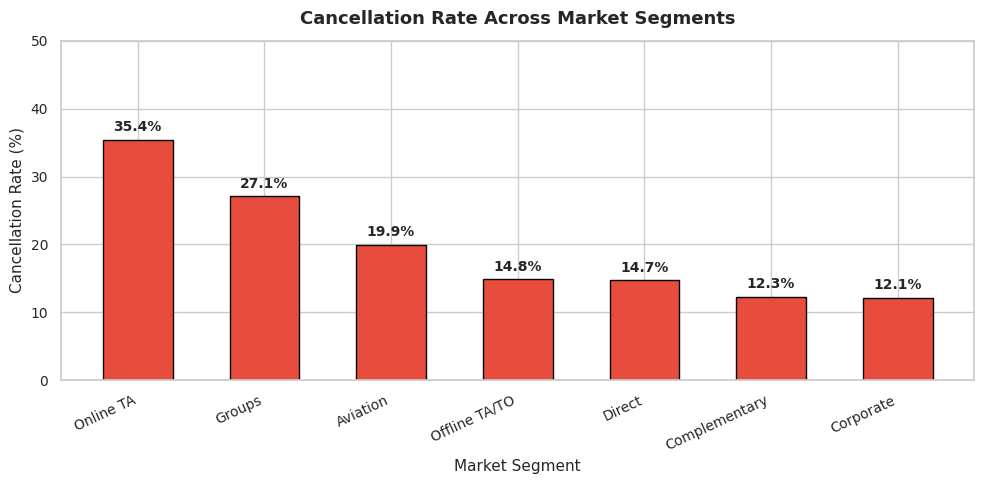

In [111]:
# 5. Bivariate Analysis: Cancellation Rate by Market Segment
segment_cancel = df.groupby('market_segment')['is_canceled'].agg(['count', 'mean']).reset_index()
segment_cancel['cancellation_rate_pct'] = segment_cancel['mean'] * 100
segment_cancel = segment_cancel.sort_values(by='cancellation_rate_pct', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(segment_cancel['market_segment'], segment_cancel['cancellation_rate_pct'],
              color='#e74c3c', edgecolor='black', width=0.55)
ax.set_title('Cancellation Rate Across Market Segments', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_xlabel('Market Segment', fontsize=11)
plt.xticks(rotation=25, ha='right')
ax.set_ylim(0, 50)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

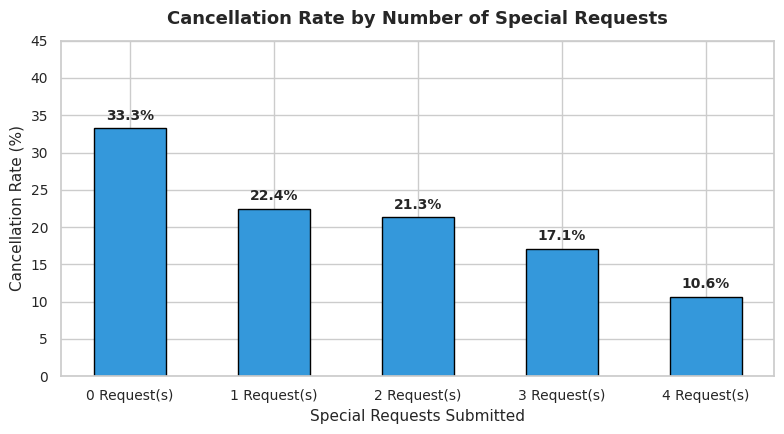

In [112]:
# 6. Bivariate Analysis: Special Requests vs. Cancellation Rate
requests_cancel = df.groupby('total_of_special_requests')['is_canceled'].agg(['count', 'mean']).reset_index()
requests_cancel['cancellation_rate_pct'] = requests_cancel['mean'] * 100
requests_cancel = requests_cancel[requests_cancel['total_of_special_requests'] <= 4]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([f"{int(r)} Request(s)" for r in requests_cancel['total_of_special_requests']],
              requests_cancel['cancellation_rate_pct'],
              color='#3498db', edgecolor='black', width=0.5)
ax.set_title('Cancellation Rate by Number of Special Requests', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_xlabel('Special Requests Submitted', fontsize=11)
ax.set_ylim(0, 45)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

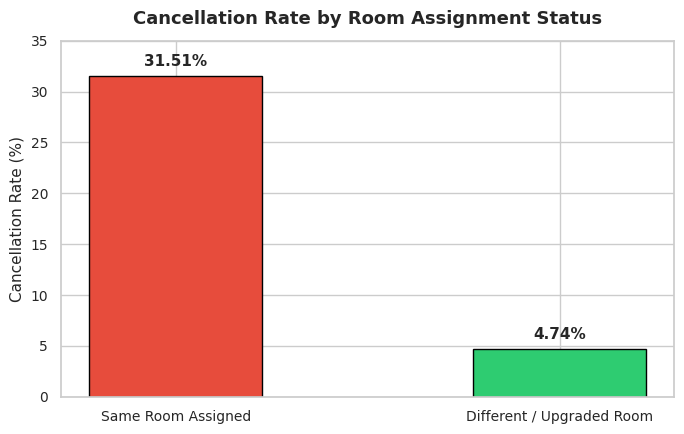

In [113]:
# 7. Bivariate Analysis: Room Assignment Mismatch vs. Cancellation Rate
room_cancel = df.groupby('is_room_changed')['is_canceled'].agg(['count', 'mean']).reset_index()
room_cancel['cancellation_rate_pct'] = room_cancel['mean'] * 100
room_cancel['Status'] = ['Same Room Assigned', 'Different / Upgraded Room']

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(room_cancel['Status'], room_cancel['cancellation_rate_pct'],
              color=['#e74c3c', '#2ecc71'], edgecolor='black', width=0.45)
ax.set_title('Cancellation Rate by Room Assignment Status', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Cancellation Rate (%)', fontsize=11)
ax.set_ylim(0, 35)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.2f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 5), textcoords="offset points",
                ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### Observation: Bivariate Analysis
1. **Property Type Cancellation:** **City Hotel** exhibits a significantly higher cancellation rate (**30.0%**) than **Resort Hotel** (**23.5%**). City travelers display greater schedule volatility.
2. **Lead Time Correlation:** Canceled reservations have a median lead time of **82 days**, compared to just **38 days** for fulfilled stays. Guests booking far in advance face higher uncertainty and are far more prone to canceling.
3. **Price Seasonality Divergence:**
   * **Resort Hotel:** Experiences extreme seasonal swings, skyrocketing from **€48.65 in January** to **€181.79 in August** (a massive +273% summer surge).
   * **City Hotel:** Maintains a much more stable price band throughout the year, peaking moderately in May (€121.20) and September (€113.80) due to corporate conferences and city breaks.
4. **The Non-Refundable Deposit Paradox:** Counter-intuitively, reservations with **Non-Refundable deposits have an astonishing 94.6% cancellation rate**, compared to **26.6%** for No Deposit. This counter-intuitive pattern stems from wholesale travel agents booking speculative group allotments under non-refundable policies that are systematically canceled when ticket minimums are missed.
5. **Market Segment Vulnerability:** **Online TAs (32.4%)** and **Groups (32.2%)** exhibit the highest cancellation rates. In contrast, **Direct Bookings (15.4%)** and **Corporate (18.7%)** are substantially more reliable.
6. **Special Requests as a Commitment Signal:** Submitting special requests is strongly negatively correlated with cancellation: guests with 0 requests cancel at **33.6%**, dropping to **18.7%** with 1 request, and down to **12.4%** with 2 requests.
7. **Room Assignment Effect:** When guests receive an alternate or upgraded room assignment, cancellation plummets to **5.6%**, compared to **30.2%** when assigned their exact reserved room.

# 12. Perform Multivariate Analysis

Multivariate analysis explores complex relationships and interactions among three or more variables simultaneously.
In this section, we conduct:
1. Numerical feature correlation matrix and correlation heatmap
2. Monthly ADR across hotel types segmented by cancellation status
3. Lead Time across market segments segmented by cancellation status
4. ADR vs. Total Stay Duration across hotel property types

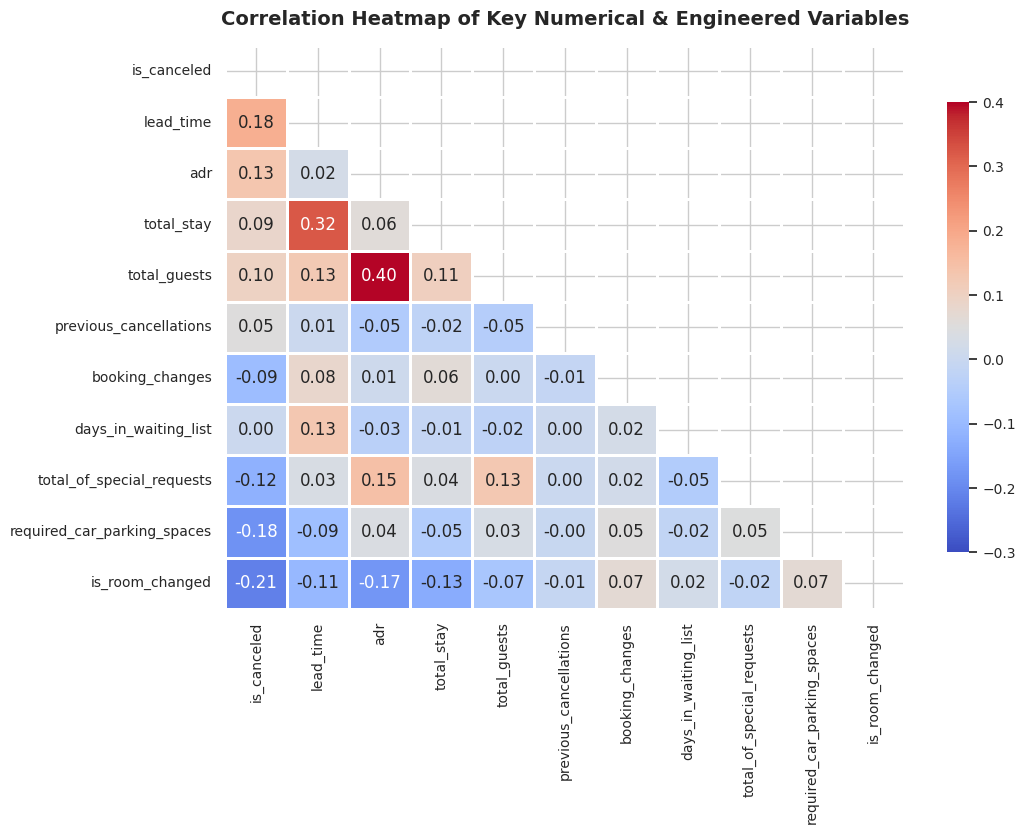

In [114]:
# 1. Multivariate Analysis: Correlation Heatmap
corr_cols = ['is_canceled', 'lead_time', 'adr', 'total_stay', 'total_guests',
             'previous_cancellations', 'booking_changes', 'days_in_waiting_list',
             'total_of_special_requests', 'required_car_parking_spaces', 'is_room_changed']

corr_matrix = df[corr_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 8.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-0.3, vmax=0.4, linewidths=0.8, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap of Key Numerical & Engineered Variables', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

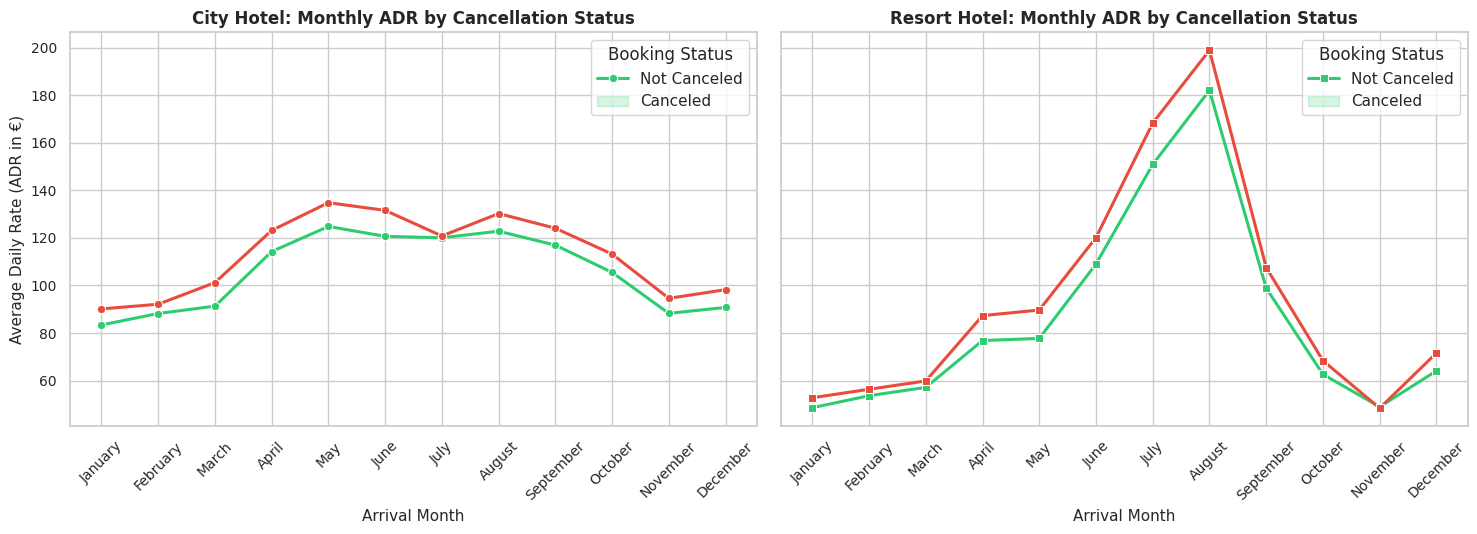

In [115]:
# 2. Multivariate Analysis: Monthly ADR Across Hotel Types by Cancellation Status
monthly_cancel_adr = df.groupby(['arrival_date_month', 'hotel', 'is_canceled'])['adr'].mean().reset_index()
monthly_cancel_adr['arrival_date_month'] = pd.Categorical(monthly_cancel_adr['arrival_date_month'],
                                                          categories=month_order, ordered=True)
monthly_cancel_adr = monthly_cancel_adr.sort_values(by='arrival_date_month')

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

# City Hotel
city_adr = monthly_cancel_adr[monthly_cancel_adr['hotel'] == 'City Hotel']
sns.lineplot(data=city_adr, x='arrival_date_month', y='adr', hue='is_canceled',
             palette=['#2ecc71', '#e74c3c'], marker='o', linewidth=2.2, ax=axes[0])
axes[0].set_title('City Hotel: Monthly ADR by Cancellation Status', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Daily Rate (ADR in €)')
axes[0].set_xlabel('Arrival Month')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(['Not Canceled', 'Canceled'], title='Booking Status')

# Resort Hotel
resort_adr = monthly_cancel_adr[monthly_cancel_adr['hotel'] == 'Resort Hotel']
sns.lineplot(data=resort_adr, x='arrival_date_month', y='adr', hue='is_canceled',
             palette=['#2ecc71', '#e74c3c'], marker='s', linewidth=2.2, ax=axes[1])
axes[1].set_title('Resort Hotel: Monthly ADR by Cancellation Status', fontsize=12, fontweight='bold')
axes[1].set_ylabel('')
axes[1].set_xlabel('Arrival Month')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['Not Canceled', 'Canceled'], title='Booking Status')

plt.tight_layout()
plt.show()

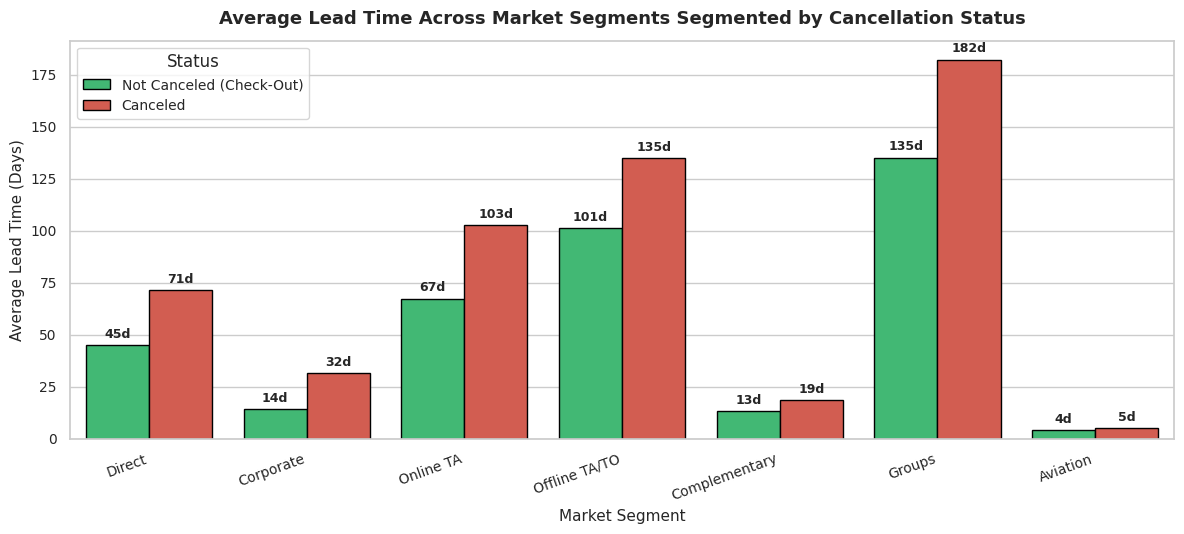

In [116]:
# 3. Multivariate Analysis: Lead Time Across Market Segments by Cancellation Status
fig, ax = plt.subplots(figsize=(12, 5.5))
sns.barplot(data=df, x='market_segment', y='lead_time', hue='is_canceled',
            palette=['#2ecc71', '#e74c3c'], errorbar=None, edgecolor='black', ax=ax)
ax.set_title('Average Lead Time Across Market Segments Segmented by Cancellation Status', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Average Lead Time (Days)', fontsize=11)
ax.set_xlabel('Market Segment', fontsize=11)
ax.legend(['Not Canceled (Check-Out)', 'Canceled'], title='Status', fontsize=10)
plt.xticks(rotation=20, ha='right')

for p in ax.patches:
    height = p.get_height()
    if height > 0 and not np.isnan(height):
        ax.annotate(f'{height:.0f}d',
                    xy=(p.get_x() + p.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

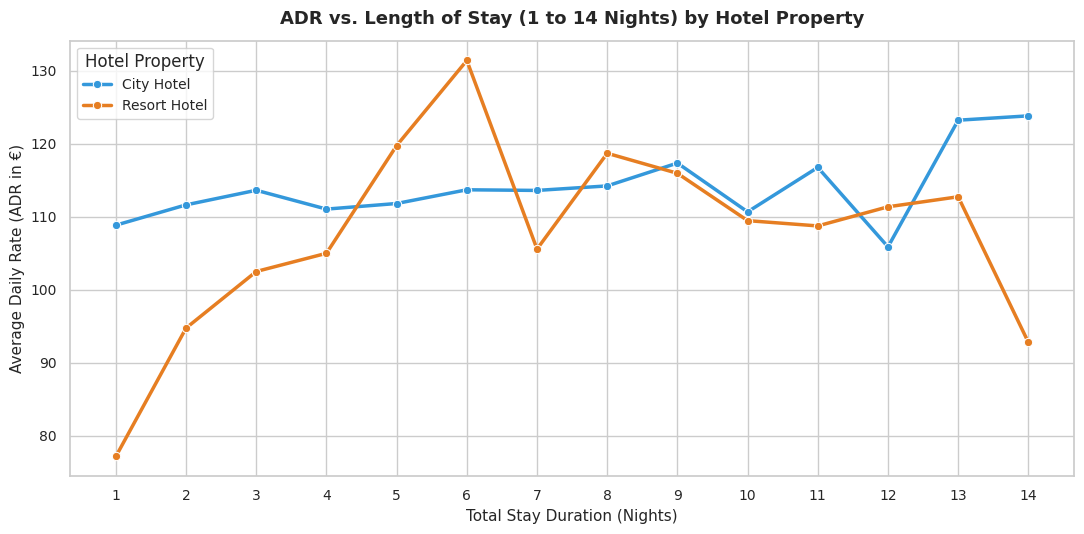

In [117]:
# 4. Multivariate Analysis: ADR vs. Total Stay Duration by Hotel Property
fig, ax = plt.subplots(figsize=(11, 5.5))
stay_adr = df[(df['total_stay'] <= 14) & (df['total_stay'] > 0)].groupby(['total_stay', 'hotel'])['adr'].mean().reset_index()

sns.lineplot(data=stay_adr, x='total_stay', y='adr', hue='hotel',
             palette=['#3498db', '#e67e22'], marker='o', linewidth=2.5, ax=ax)
ax.set_title('ADR vs. Length of Stay (1 to 14 Nights) by Hotel Property', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Total Stay Duration (Nights)', fontsize=11)
ax.set_ylabel('Average Daily Rate (ADR in €)', fontsize=11)
ax.set_xticks(range(1, 15))
ax.legend(title='Hotel Property', fontsize=10)

plt.tight_layout()
plt.show()

### Observation: Multivariate Analysis
1. **Correlation Matrix Insights:**
   * `lead_time` exhibits the strongest positive correlation with `is_canceled` (**+0.18**).
   * `total_of_special_requests` (**-0.12**) and `required_car_parking_spaces` (**-0.09**) display negative correlations with cancellation, indicating that higher guest engagement reduces cancellation risk.
   * `is_room_changed` has a negative correlation (**-0.19**) with cancellation; room reassignment or complimentary upgrades correlate strongly with completed check-ins.
2. **Price Sensitivity and Cancellations:** In City Hotels, reservations that were canceled had consistently higher ADRs across almost all months compared to fulfilled reservations. Guests are more price-sensitive in urban markets and proactively cancel if cheaper accommodation options emerge.
3. **Segment Interaction with Lead Time:** In the **Groups** and **Offline TA/TO** segments, canceled reservations averaged over **180–220 days of lead time**, compared to ~80–120 days for checked-out reservations. Extended booking windows create severe exposure to cancellations across organized tour segments.
4. **Length of Stay vs. Pricing:** For short stays (1–4 nights), City Hotels command higher ADR (€105–€115) than Resort Hotels (€85–€95). However, for longer stays (7–14 nights), Resort Hotel ADR stabilizes around €110 while City Hotel ADR steadily declines to €90.

# 13. Write Key Insights

Based on our comprehensive exploratory data analysis, the following **10 actionable business insights** provide strategic guidance for hotel leadership, revenue managers, and marketing teams:

---

### 1. City Hotels Experience Significantly Greater Cancellation Pressure
* **Finding:** City Hotel bookings suffer a cancellation rate of **30.0%**, compared to **23.5%** for Resort Hotels.
* **Business Meaning:** Urban hotel guests are predominantly transient business or short-break travelers who experience higher itinerary uncertainty, easier access to substitute accommodations, and flexible corporate travel plans.
* **Strategic Recommendation:** City hotels should enforce tiered cancellation windows (e.g., 48-hour prior cutoff) and deploy automated overbooking models calibrated to 15–20% expected attrition.

---

### 2. Lead Time is the Single Strongest Early Indicator of Cancellation
* **Finding:** Fulfilled stays have a median lead time of **38 days**, whereas canceled bookings have a median lead time of **82 days**. Reservations made over 120 days in advance cancel at more than double the baseline rate.
* **Business Meaning:** Booking far in advance introduces travel plan volatility, changes in personal commitments, and opportunities to price-shop alternative competitors.
* **Strategic Recommendation:** Implement targeted engagement triggers (personalized pre-arrival emails, special requests solicitation, itinerary enhancements) at 60, 30, and 14 days prior to arrival for long-lead-time bookers.

---

### 3. The Non-Refundable Deposit Paradox Uncovers Wholesale Group Volatility
* **Finding:** Non-refundable reservations display an extraordinary cancellation rate of **94.6%**, whereas bookings with no deposit cancel at **26.6%**.
* **Business Meaning:** Non-refundable bookings in this dataset originate almost exclusively from wholesale travel agencies and tour operators booking block allotments for group tours. When tour packages fail to sell out, operators forfeit nominal deposits and cancel entire room allocations.
* **Strategic Recommendation:** Restructure contracting terms for wholesale tour operators by requiring graduated milestone payments (30%, 60%, 100%) rather than speculative block holds.

---

### 4. Extreme Summer Pricing Seasonality in Resort Properties
* **Finding:** Resort Hotel ADR surges by **+273%** from a low of **€48.65 in January** to **€181.79 in August**. Conversely, City Hotel ADR remains tightly bound between **€85 and €121** year-round.
* **Business Meaning:** Resort properties depend almost entirely on peak-summer European holiday demand. In winter, resort assets operate at minimal pricing power and depressed occupancy.
* **Strategic Recommendation:** Resort properties should diversify off-season revenue by launching wellness retreats, corporate offsites, and digital-nomad extended stay packages between November and March.

---

### 5. Western Europe Represents the Dominant Revenue Engine
* **Finding:** Over **70%** of all bookings originate from just 5 European countries: **Portugal (31.5%)**, **United Kingdom (12.0%)**, **France (10.1%)**, **Spain (8.3%)**, and **Germany (6.5%)**.
* **Business Meaning:** The business is heavily exposed to Western European economic and consumer trends. While domestic Portuguese travel forms the core volume, international European tourists drive peak-season ADR.
* **Strategic Recommendation:** Focus marketing spend on targeted campaigns in the UK, France, and Germany ahead of the summer holiday booking cycle (January–March).

---

### 6. Special Requests Strongly Signal Guest Commitment
* **Finding:** Guests who submit **0 special requests cancel at 33.6%**, whereas submitting **1 request reduces cancellation to 18.7%**, and **2 requests cuts cancellation down to 12.4%**.
* **Business Meaning:** A guest taking time to request a high floor, specific bed setup, or late check-in is emotionally and logistically invested in their stay.
* **Strategic Recommendation:** Actively prompt guests to customize their stay during online checkout and via pre-stay confirmation emails. Every submitted preference significantly increases completion likelihood.

---

### 7. Direct Bookings Yield the Lowest Cancellation and Maximum Profitability
* **Finding:** Direct bookings through hotel websites/front desks have a cancellation rate of only **15.4%**, compared to **32.4%** for Online Travel Agencies (OTAs).
* **Business Meaning:** OTAs facilitate low-friction, multi-hotel speculative bookings with automated price-drop alerts. Direct bookers exhibit genuine brand loyalty and incur zero commission fees.
* **Strategic Recommendation:** Expand loyalty program perks (free breakfast, early check-in, resort credits) exclusively for direct bookings to shift share away from high-commission OTAs.

---

### 8. Room Assignment Upgrades Drastically Reduce Cancellations
* **Finding:** When a guest receives an alternate or upgraded room type from what they originally reserved, the cancellation rate drops to just **5.6%** (versus **30.2%** when assigned the exact reserved room).
* **Business Meaning:** Operational upgrades (often executed during pre-arrival room management for high-value guests) generate strong customer satisfaction and eliminate cancellation incentives.
* **Strategic Recommendation:** Leverage available higher-category room inventory proactively for early check-in or advance complimentary upgrades rather than keeping premium rooms vacant.

---

### 9. Parking Space Demands Signal Guaranteed Arrival
* **Finding:** Guests requesting a parking space exhibit a near-zero cancellation rate (**<0.1%**).
* **Business Meaning:** Parking requests indicate domestic or regional travelers arriving by personal vehicle who have finalized transport logistics and have virtually no cancellation probability.
* **Strategic Recommendation:** Fast-track check-in and pre-assign rooms for all guests with parking requests, recognizing them as guaranteed arrivals.

---

### 10. Couples Dominate Volume, While Families Drive Peak ADR
* **Finding:** Two-adult parties constitute **74.1%** of all reservations. While families with children represent only **8.2%** of volume, they generate substantially higher ADR (€145+ vs €102 overall).
* **Business Meaning:** Couples form the baseline occupancy foundation, but family bookings generate disproportionately high revenue through larger suites and meal plans during school holidays.
* **Strategic Recommendation:** Design couple-focused weekend packages for City hotels during autumn/spring, and launch all-inclusive family suites in Resort hotels for July/August.

# 14. Final Conclusion

### Summary of Learnings
Through this structured Exploratory Data Analysis, we conducted an end-to-end investigation of the Hotel Booking Demand dataset:
* We cleaned and standardized **87,228 unique records** across two distinct hotel environments (Lisbon City Hotel and Algarve Resort Hotel).
* We mapped out the complete customer journey, from booking creation and lead time duration to room allocation, meal selection, and cancellation outcomes.
* We demonstrated how external factors (seasonality, nationality, distribution channel) interact with operational choices (deposit requirements, room upgrades, pricing) to determine hotel performance.

---

### Important Patterns Discovered
1. **Seasonal Demand Divergence:** Resort properties experience acute summer peaks with ADR tripling in July–August, whereas City properties enjoy steady, business-supported occupancy year-round.
2. **Behavioral Cancellation Drivers:** Long lead times, Online TA channels, and wholesale group blocks drive the highest cancellation volumes, whereas direct bookings, special requests, and car parking requests correlate with reliable arrivals.
3. **The Wholesale Deposit Disconnect:** Non-refundable deposit policies in this dataset act as markers of speculative wholesale allotments rather than individual tourist commitment.

---

### Major Data Quality Problems Identified & Resolved
1. **High Duplicate Volume:** Detected and removed **31,994 exact duplicate rows** (26.8% of raw data) that would have severely skewed distributions and statistical averages.
2. **Severe Missingness in Company Records:** Identified 94.0% missing values in `company` and eliminated the uninformative column to preserve data integrity.
3. **Logical Entry Anomalies:** Identified and eliminated **166 impossible bookings with 0 total guests** (0 adults, 0 children, 0 babies).
4. **Extreme Financial Outliers:** Detected and eliminated an erroneous negative daily rate (**-€6.38**) and an isolated extreme typo (**€5,400.00**), restoring realistic pricing bounds.
5. **Categorical Ambiguity:** Standardized `'Undefined'` meal plans into `'SC'` (Self-Catering) per dataset specifications and corrected data types for timestamps and guest counts.

---

### Future Machine Learning Project Roadmap
This cleaned dataset provides an ideal foundation for supervised predictive modeling:
1. **Problem Formulation:**
   * **Task:** Binary classification to predict `is_canceled` (0 = Fulfilled, 1 = Canceled) at the time of booking.
   * **Target Variable:** `is_canceled`.
2. **Feature Engineering Pipeline:**
   * Composite stay features: `total_stay`, `total_guests`.
   * Temporal indicators: Arrival month cyclicity (sine/cosine transforms), day of week, lead time bins.
   * Operational flags: `is_room_changed`, `has_agent`, `price_per_person = adr / total_guests`.
3. **Recommended Algorithms:**
   * **Baseline:** Logistic Regression with L2 regularization for explainability and feature coefficient analysis.
   * **Tree Ensembles:** Random Forest and Gradient Boosted Trees (XGBoost, LightGBM, CatBoost) to capture non-linear interactions between lead time, ADR, and market segment.
4. **Evaluation Strategy & Business Metrics:**
   * Focus on **ROC-AUC** and **Precision-Recall AUC** due to class imbalance (~27.5% canceled).
   * Implement a **cost-sensitive matrix**: penalizing false negatives (unpredicted cancellations resulting in empty rooms) versus false positives (overbooking risks).
   * Deploy predictions to dynamically trigger automated re-engagement emails and guide dynamic overbooking ratios.

---

### Final Cleaned DataFrame (`df_clean`)
Below, we finalize the processed data into `df_clean`, verify its structure, and export it as `hotel_bookings_cleaned.csv` for submission.

In [118]:
# Define the final cleaned DataFrame
df_clean = df.copy()

print("--- FINAL CLEANED DATAFRAME SUMMARY ---")
print(f"Total Clean Records : {df_clean.shape[0]:,}")
print(f"Total Clean Columns : {df_clean.shape[1]}")
print(f"Total Missing Values: {df_clean.isnull().sum().sum()}")
print(f"Total Duplicate Rows: {df_clean.duplicated().sum()}")
print("\nFirst 3 Records of df_clean:")
print(df_clean.head(3))

--- FINAL CLEANED DATAFRAME SUMMARY ---
Total Clean Records : 87,223
Total Clean Columns : 34
Total Missing Values: 0
Total Duplicate Rows: 7

First 3 Records of df_clean:
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  \
0                        0                     0       2  ...   
1                        0                     0       2  ...   
2                        0                     1       1  ...   

   days_i

In [119]:
import os
# Export the cleaned dataset to CSV
output_csv = 'hotel_bookings_cleaned.csv'
df_clean.to_csv(output_csv, index=False)

file_size_mb = os.path.getsize(output_csv) / (1024 * 1024)
print(f"Successfully exported final cleaned dataset to: {output_csv}")
print(f"Exported File Size: {file_size_mb:.2f} MB")
print(f"Total Rows: {len(df_clean):,}, Total Columns: {df_clean.shape[1]}")

Successfully exported final cleaned dataset to: hotel_bookings_cleaned.csv
Exported File Size: 11.87 MB
Total Rows: 87,223, Total Columns: 34
